In [1]:
from pathlib import Path

import pandas as pd
import torch

from PIL import Image
from transformers import (
    Pix2StructForConditionalGeneration,
    Pix2StructProcessor
)


# --------------------------------------------------
# Project paths
# --------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

ORACLE_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "oracle_e5"
)

DEPLOT_OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "deplot"
)

MODEL_CACHE_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "model_cache"
)

DEPLOT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# Load chart-table mapping
# --------------------------------------------------

oracle_charts_path = (
    ORACLE_DATA_DIR
    / "oracle_chart_table_mapping.parquet"
)

assert oracle_charts_path.exists(), (
    "Oracle chart mapping was not found."
)

oracle_charts_df = pd.read_parquet(
    oracle_charts_path
)

print("Charts loaded:", len(oracle_charts_df))


# --------------------------------------------------
# Select one original-data chart per chart type
# --------------------------------------------------

available_chart_types = [
    "v_bar",
    "h_bar",
    "line",
    "pie"
]

smoke_charts_df = (
    oracle_charts_df[
        (
            oracle_charts_df[
                "table_variant_type"
            ] == "original"
        )
        &
        (
            oracle_charts_df[
                "chart_type"
            ].isin(available_chart_types)
        )
    ]
    .sort_values(
        [
            "chart_type",
            "chart_id"
        ]
    )
    .groupby(
        "chart_type",
        sort=False
    )
    .head(1)
    .reset_index(drop=True)
    .copy()
)

smoke_charts_df["image_exists_now"] = (
    smoke_charts_df["image_path"]
    .apply(
        lambda path: Path(path).exists()
    )
)

print("\nSmoke-test charts")

display(
    smoke_charts_df[
        [
            "chart_id",
            "chart_type",
            "variant_type",
            "image_path",
            "image_exists_now"
        ]
    ]
)

assert len(smoke_charts_df) == 4
assert smoke_charts_df["image_exists_now"].all()


# --------------------------------------------------
# Load DePlot
# --------------------------------------------------

DEPLOT_MODEL_NAME = "google/deplot"

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model_dtype = (
    torch.float16
    if device == "cuda"
    else torch.float32
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Loading:", DEPLOT_MODEL_NAME)

deplot_processor = (
    Pix2StructProcessor.from_pretrained(
        DEPLOT_MODEL_NAME,
        cache_dir=str(MODEL_CACHE_DIR)
    )
)

deplot_model = (
    Pix2StructForConditionalGeneration
    .from_pretrained(
        DEPLOT_MODEL_NAME,
        cache_dir=str(MODEL_CACHE_DIR),
        torch_dtype=model_dtype,
        low_cpu_mem_usage=True
    )
    .to(device)
    .eval()
)

print("DePlot loaded successfully")
print(
    "Model dtype:",
    next(deplot_model.parameters()).dtype
)


# --------------------------------------------------
# DePlot inference function
# --------------------------------------------------

DEPLOT_PROMPT = (
    "Generate underlying data table of the figure below:"
)


def extract_table_with_deplot(image_path):
    image = (
        Image.open(image_path)
        .convert("RGB")
    )

    inputs = deplot_processor(
        images=image,
        text=DEPLOT_PROMPT,
        return_tensors="pt",
        max_patches=2048
    )

    prepared_inputs = {}

    for input_name, input_tensor in inputs.items():

        if torch.is_floating_point(input_tensor):
            prepared_inputs[input_name] = (
                input_tensor.to(
                    device=device,
                    dtype=model_dtype
                )
            )
        else:
            prepared_inputs[input_name] = (
                input_tensor.to(device)
            )

    with torch.inference_mode():
        generated_ids = deplot_model.generate(
            **prepared_inputs,
            max_new_tokens=512,
            num_beams=1,
            do_sample=False
        )

    extracted_text = deplot_processor.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    image.close()

    return extracted_text.strip()


# --------------------------------------------------
# Run four-chart smoke test
# --------------------------------------------------

smoke_results = []

for _, chart_row in smoke_charts_df.iterrows():

    print(
        "\nExtracting:",
        chart_row["chart_type"],
        chart_row["chart_id"]
    )

    try:
        predicted_table = (
            extract_table_with_deplot(
                chart_row["image_path"]
            )
        )

        extraction_status = "success"
        error_message = None

    except Exception as error:
        predicted_table = None
        extraction_status = "failed"
        error_message = str(error)

    smoke_results.append(
        {
            "chart_id": chart_row["chart_id"],
            "data_id": chart_row["data_id"],
            "source_data_id": (
                chart_row["source_data_id"]
            ),
            "chart_type": chart_row["chart_type"],
            "variant_type": (
                chart_row["variant_type"]
            ),
            "image_path": chart_row["image_path"],
            "deplot_raw_text": predicted_table,
            "ground_truth_table_text": (
                chart_row[
                    "canonical_table_text"
                ]
            ),
            "extraction_status": (
                extraction_status
            ),
            "error_message": error_message
        }
    )


smoke_results_df = pd.DataFrame(
    smoke_results
)


# --------------------------------------------------
# Display extracted and ground-truth tables
# --------------------------------------------------

for _, result_row in smoke_results_df.iterrows():

    print("\n" + "=" * 80)
    print(
        "CHART TYPE:",
        result_row["chart_type"]
    )
    print(
        "CHART ID:",
        result_row["chart_id"]
    )
    print(
        "STATUS:",
        result_row["extraction_status"]
    )

    print("\nDEPLOT OUTPUT")
    print(result_row["deplot_raw_text"])

    print("\nGROUND-TRUTH TABLE")
    print(result_row["ground_truth_table_text"])


# --------------------------------------------------
# Save smoke-test output
# --------------------------------------------------

smoke_output_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_smoke_outputs.parquet"
)

smoke_results_df.to_parquet(
    smoke_output_path,
    index=False
)

print("\nSmoke output saved:", smoke_output_path)
print("File exists:", smoke_output_path.exists())

Charts loaded: 4104

Smoke-test charts


,chart_id,chart_type,variant_type,image_path,image_exists_now
0,chartqa_test_15359798001840__hbar_orange,h_bar,positive,/home/pnola130/projects/chart_data_retrieval/g...,True
1,chartqa_test_15359798001840__line_green,line,hard_positive,/home/pnola130/projects/chart_data_retrieval/g...,True
2,chartqa_test_15359798001840__pie_palette,pie,hard_positive,/home/pnola130/projects/chart_data_retrieval/g...,True
3,chartqa_test_15359798001840__vbar_blue,v_bar,anchor,/home/pnola130/projects/chart_data_retrieval/g...,True



Device: cuda
GPU: NVIDIA A100-SXM4-80GB MIG 2g.20gb
Loading: google/deplot


preprocessor_config.json:   0%|          | 0.00/249 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/851k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors:   0%|          | 0.00/1.13G [00:00<?, ?B/s]

DePlot loaded successfully
Model dtype: torch.float16

Extracting: h_bar chartqa_test_15359798001840__hbar_orange


Arial.TTF: 0.00B [00:00, ?B/s]


Extracting: line chartqa_test_15359798001840__line_green

Extracting: pie chartqa_test_15359798001840__pie_palette

Extracting: v_bar chartqa_test_15359798001840__vbar_blue

CHART TYPE: h_bar
CHART ID: chartqa_test_15359798001840__hbar_orange
STATUS: success

DEPLOT OUTPUT
TITLE | Distribution of job finding methods for employed workers in Europeancountries, Greece <0x0A>Country | Distribution of job finding methods for employed workers in Europeancountries, Greece<0x0A>Agencies | 1.60<0x0A>Adverts | 7.50<0x0A>Other | 14.50<0x0A>Direct applications | 36.20<0x0A>Personal contacts | 40.90

GROUND-TRUTH TABLE
table columns: Country | Distribution of job finding methods for employed workers in Europeancountries, Greece. row 1: Country = Personal contacts ; Distribution of job finding methods for employed workers in Europeancountries, Greece = 41. row 2: Country = Direct applications ; Distribution of job finding methods for employed workers in Europeancountries, Greece = 36. row 3: Countr

In [2]:
import json

import numpy as np
import pandas as pd

from tqdm import tqdm


# --------------------------------------------------
# Load structured tables for row-count information
# --------------------------------------------------

canonical_tables_path = (
    ORACLE_DATA_DIR
    / "canonical_tables.parquet"
)

canonical_tables_df = pd.read_parquet(
    canonical_tables_path
)


def count_rows(rows_json):
    if isinstance(rows_json, str):
        rows = json.loads(rows_json)
    elif isinstance(rows_json, np.ndarray):
        rows = rows_json.tolist()
    else:
        rows = rows_json

    return len(rows)


table_audit_metadata = (
    canonical_tables_df[
        [
            "data_id",
            "columns_json",
            "rows_json"
        ]
    ]
    .copy()
)

table_audit_metadata["num_rows"] = (
    table_audit_metadata[
        "rows_json"
    ].apply(count_rows)
)

audit_source_df = oracle_charts_df.merge(
    table_audit_metadata,
    on="data_id",
    how="left",
    validate="many_to_one"
)

assert audit_source_df["num_rows"].notna().all()


# --------------------------------------------------
# Audit sampling configuration
# --------------------------------------------------

AUDIT_SAMPLE_SIZE_PER_TYPE = 25

split_quotas = {
    "train": 17,
    "val": 4,
    "test": 4
}

audit_sample_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_audit_sample.parquet"
)

audit_output_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_audit_outputs.parquet"
)


# --------------------------------------------------
# Create or reload the fixed audit sample
# --------------------------------------------------

if audit_sample_path.exists():

    audit_sample_df = pd.read_parquet(
        audit_sample_path
    )

    print(
        "Loaded existing audit sample:",
        len(audit_sample_df)
    )

else:

    selected_groups = []

    for type_number, chart_type in enumerate(
        ["v_bar", "h_bar", "line", "pie"]
    ):

        chart_type_pool = (
            audit_source_df[
                audit_source_df["chart_type"]
                == chart_type
            ]
            .copy()
        )

        selected_for_type = []

        for split_number, (
            split_name,
            required_count
        ) in enumerate(split_quotas.items()):

            split_pool = (
                chart_type_pool[
                    chart_type_pool["split"]
                    == split_name
                ]
                .copy()
            )

            selected_split_parts = []

            # Try to include both original and shuffled data
            # whenever both are available.
            requested_original = (
                required_count + 1
            ) // 2

            requested_negative = (
                required_count
                - requested_original
            )

            variant_requests = {
                "original": requested_original,
                "hard_negative": requested_negative
            }

            selected_ids = set()

            for variant_number, (
                table_variant,
                requested_number
            ) in enumerate(
                variant_requests.items()
            ):

                variant_pool = (
                    split_pool[
                        split_pool[
                            "table_variant_type"
                        ]
                        == table_variant
                    ]
                    .copy()
                )

                number_to_sample = min(
                    requested_number,
                    len(variant_pool)
                )

                if number_to_sample > 0:

                    sampled_part = (
                        variant_pool.sample(
                            n=number_to_sample,
                            random_state=(
                                42
                                + type_number * 100
                                + split_number * 10
                                + variant_number
                            )
                        )
                    )

                    selected_split_parts.append(
                        sampled_part
                    )

                    selected_ids.update(
                        sampled_part[
                            "chart_id"
                        ].tolist()
                    )

            selected_count = sum(
                len(part)
                for part in selected_split_parts
            )

            remaining_needed = (
                required_count
                - selected_count
            )

            if remaining_needed > 0:

                remaining_pool = (
                    split_pool[
                        ~split_pool[
                            "chart_id"
                        ].isin(selected_ids)
                    ]
                )

                assert (
                    len(remaining_pool)
                    >= remaining_needed
                )

                fill_part = remaining_pool.sample(
                    n=remaining_needed,
                    random_state=(
                        900
                        + type_number * 100
                        + split_number
                    )
                )

                selected_split_parts.append(
                    fill_part
                )

            selected_split_df = pd.concat(
                selected_split_parts,
                ignore_index=True
            )

            assert (
                len(selected_split_df)
                == required_count
            )

            selected_for_type.append(
                selected_split_df
            )

        selected_type_df = pd.concat(
            selected_for_type,
            ignore_index=True
        )

        assert (
            len(selected_type_df)
            == AUDIT_SAMPLE_SIZE_PER_TYPE
        )

        selected_groups.append(
            selected_type_df
        )

    audit_sample_df = pd.concat(
        selected_groups,
        ignore_index=True
    )

    audit_sample_df = (
        audit_sample_df
        .sample(
            frac=1,
            random_state=42
        )
        .reset_index(drop=True)
    )

    audit_sample_df.to_parquet(
        audit_sample_path,
        index=False
    )

    print(
        "Created audit sample:",
        len(audit_sample_df)
    )


# --------------------------------------------------
# Validate sample composition
# --------------------------------------------------

assert len(audit_sample_df) == 100
assert audit_sample_df["image_path"].apply(
    lambda path: Path(path).exists()
).all()

print("\nAudit sample by chart type")

display(
    pd.crosstab(
        audit_sample_df["chart_type"],
        audit_sample_df["table_variant_type"],
        margins=True
    )
)

print("\nAudit sample by split")

display(
    pd.crosstab(
        audit_sample_df["chart_type"],
        audit_sample_df["split"],
        margins=True
    )
)

print("\nRow-count statistics")

display(
    audit_sample_df.groupby(
        "chart_type"
    )["num_rows"].agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max"
        ]
    ).round(2)
)


# --------------------------------------------------
# Reload previous progress if available
# --------------------------------------------------

if audit_output_path.exists():

    completed_outputs_df = pd.read_parquet(
        audit_output_path
    )

    completed_chart_ids = set(
        completed_outputs_df[
            "chart_id"
        ].tolist()
    )

    audit_results = (
        completed_outputs_df
        .to_dict(orient="records")
    )

    print(
        "\nPreviously completed:",
        len(completed_chart_ids)
    )

else:

    completed_chart_ids = set()
    audit_results = []


remaining_audit_df = audit_sample_df[
    ~audit_sample_df["chart_id"].isin(
        completed_chart_ids
    )
].copy()

print(
    "Remaining charts:",
    len(remaining_audit_df)
)


# --------------------------------------------------
# Run DePlot audit with checkpointing
# --------------------------------------------------

for completed_number, (
    _,
    chart_row
) in enumerate(
    tqdm(
        remaining_audit_df.iterrows(),
        total=len(remaining_audit_df),
        desc="Running DePlot audit"
    ),
    start=1
):

    try:
        extracted_table = (
            extract_table_with_deplot(
                chart_row["image_path"]
            )
        )

        extraction_status = "success"
        error_message = None

    except Exception as error:
        extracted_table = None
        extraction_status = "failed"
        error_message = str(error)

    audit_results.append(
        {
            "chart_id": chart_row["chart_id"],
            "data_id": chart_row["data_id"],
            "source_data_id": (
                chart_row["source_data_id"]
            ),
            "split": chart_row["split"],
            "chart_type": chart_row["chart_type"],
            "style_id": chart_row["style_id"],
            "variant_type": (
                chart_row["variant_type"]
            ),
            "table_variant_type": (
                chart_row["table_variant_type"]
            ),
            "num_rows": int(
                chart_row["num_rows"]
            ),
            "image_path": chart_row["image_path"],
            "deplot_raw_text": extracted_table,
            "ground_truth_columns_json": (
                chart_row["columns_json"]
            ),
            "ground_truth_rows_json": (
                chart_row["rows_json"]
            ),
            "ground_truth_table_text": (
                chart_row[
                    "canonical_table_text"
                ]
            ),
            "extraction_status": (
                extraction_status
            ),
            "error_message": error_message
        }
    )

    # Save every five newly processed charts
    if (
        completed_number % 5 == 0
        or completed_number
        == len(remaining_audit_df)
    ):

        checkpoint_df = (
            pd.DataFrame(audit_results)
            .drop_duplicates(
                subset="chart_id",
                keep="last"
            )
            .reset_index(drop=True)
        )

        checkpoint_df.to_parquet(
            audit_output_path,
            index=False
        )


# --------------------------------------------------
# Final audit status
# --------------------------------------------------

deplot_audit_df = pd.read_parquet(
    audit_output_path
)

print("\nAudit extraction completed")
print("Saved outputs:", len(deplot_audit_df))

print("\nExtraction status")

display(
    deplot_audit_df[
        "extraction_status"
    ].value_counts(
        dropna=False
    ).to_frame("count")
)

print("\nStatus by chart type")

display(
    pd.crosstab(
        deplot_audit_df["chart_type"],
        deplot_audit_df[
            "extraction_status"
        ],
        margins=True
    )
)

print("\nSaved:", audit_output_path)
print("File exists:", audit_output_path.exists())

Created audit sample: 100

Audit sample by chart type


table_variant_type,hard_negative,original,All
chart_type,,,
h_bar,0,25,25
line,12,13,25
pie,12,13,25
v_bar,12,13,25
All,36,64,100



Audit sample by split


split,test,train,val,All
chart_type,,,,
h_bar,4,17,4,25
line,4,17,4,25
pie,4,17,4,25
v_bar,4,17,4,25
All,16,68,16,100



Row-count statistics


,count,mean,median,min,max
chart_type,,,,,
h_bar,25,8.00,9.0,3,14
line,25,8.52,9.0,3,15
pie,25,5.64,6.0,3,8
v_bar,25,8.20,9.0,3,15


... (3 outputs left out)

,count
extraction_status,
success,100



Status by chart type


extraction_status,success,All
chart_type,,
h_bar,25,25
line,25,25
pie,25,25
v_bar,25,25
All,100,100



Saved: /home/pnola130/projects/chart_data_retrieval/data/derived/deplot/deplot_audit_outputs.parquet
File exists: True


In [4]:
import json
import math
import re
import unicodedata

from difflib import SequenceMatcher

import numpy as np
import pandas as pd

from scipy.optimize import linear_sum_assignment


# --------------------------------------------------
# Parsing helpers
# --------------------------------------------------

def load_json_array(value):
    if isinstance(value, str):
        return json.loads(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, tuple):
        return list(value)

    if isinstance(value, list):
        return value

    return []


def normalize_label(value):
    if value is None:
        return ""

    text = unicodedata.normalize(
        "NFKD",
        str(value)
    )

    text = text.lower().strip()

    # Remove punctuation while preserving letters/numbers
    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text
    )

    return re.sub(
        r"\s+",
        " ",
        text
    ).strip()


def label_similarity(first, second):
    first = normalize_label(first)
    second = normalize_label(second)

    if not first and not second:
        return 1.0

    if not first or not second:
        return 0.0

    if first == second:
        return 1.0

    return SequenceMatcher(
        None,
        first,
        second
    ).ratio()


def parse_numeric(value):
    """
    Extract a numeric value from strings such as:
    41.10, 7%, $1,200, -4.2, (5.3), 1.2K.
    """

    if value is None:
        return None

    text = str(value).strip()

    if not text:
        return None

    text = (
        text.replace("−", "-")
        .replace("–", "-")
        .replace("—", "-")
    )

    is_parenthesized_negative = (
        text.startswith("(")
        and text.endswith(")")
    )

    numeric_match = re.search(
        r"[-+]?"
        r"(?:\d{1,3}(?:,\d{3})+|\d+)"
        r"(?:\.\d+)?"
        r"(?:[eE][-+]?\d+)?",
        text
    )

    if numeric_match is None:
        return None

    numeric_text = (
        numeric_match.group(0)
        .replace(",", "")
    )

    try:
        number = float(numeric_text)
    except ValueError:
        return None

    if is_parenthesized_negative:
        number = -abs(number)

    suffix_text = text[
        numeric_match.end():
    ].strip().lower()

    if suffix_text.startswith("k"):
        number *= 1_000
    elif suffix_text.startswith("m"):
        number *= 1_000_000
    elif suffix_text.startswith("b"):
        number *= 1_000_000_000

    return number


# --------------------------------------------------
# Parse DePlot output
# --------------------------------------------------

def parse_deplot_output(raw_text):

    parsed_result = {
        "parse_success": False,
        "title": None,
        "header": [],
        "rows": [],
        "number_of_lines": 0
    }

    if raw_text is None:
        return parsed_result

    raw_text = str(raw_text).strip()

    if not raw_text:
        return parsed_result

    normalized_output = re.sub(
        r"<0x0a>",
        "\n",
        raw_text,
        flags=re.IGNORECASE
    )

    lines = [
        line.strip()
        for line in normalized_output.splitlines()
        if line.strip()
    ]

    parsed_result["number_of_lines"] = len(lines)

    header = []
    parsed_rows = []

    for line in lines:

        cells = [
            cell.strip()
            for cell in line.split("|")
        ]

        if len(cells) < 2:
            continue

        first_cell = normalize_label(
            cells[0]
        )

        # DePlot normally emits:
        # TITLE | chart title
        if first_cell == "title":
            parsed_result["title"] = (
                " | ".join(cells[1:]).strip()
            )
            continue

        numeric_values = [
            parse_numeric(cell)
            for cell in cells[1:]
        ]

        has_numeric_value = any(
            value is not None
            for value in numeric_values
        )

        if has_numeric_value:

            parsed_rows.append(
                {
                    "category": cells[0],
                    "raw_values": cells[1:],
                    "numeric_values": (
                        numeric_values
                    )
                }
            )

        elif not header:
            # First nonnumeric row after TITLE
            # is treated as the table header.
            header = cells

    parsed_result["header"] = header
    parsed_result["rows"] = parsed_rows
    parsed_result["parse_success"] = (
        len(parsed_rows) > 0
    )

    return parsed_result


# --------------------------------------------------
# Evaluate one extracted table
# --------------------------------------------------

CATEGORY_MATCH_THRESHOLD = 0.80
VALUE_ALIGNMENT_CATEGORY_THRESHOLD = 0.50


def evaluate_extracted_table(
    parsed_output,
    ground_truth_columns_json,
    ground_truth_rows_json
):

    ground_truth_columns = load_json_array(
        ground_truth_columns_json
    )

    ground_truth_rows = load_json_array(
        ground_truth_rows_json
    )

    predicted_rows = parsed_output["rows"]

    number_ground_truth_rows = len(
        ground_truth_rows
    )

    number_predicted_rows = len(
        predicted_rows
    )

    if number_ground_truth_rows == 0:
        row_coverage = 0.0
    else:
        row_coverage = min(
            number_predicted_rows,
            number_ground_truth_rows
        ) / number_ground_truth_rows

    exact_row_count = int(
        number_predicted_rows
        == number_ground_truth_rows
    )

    # Ground-truth category is the first cell.
    ground_truth_categories = [
        row[0] if len(row) > 0 else ""
        for row in ground_truth_rows
    ]

    predicted_categories = [
        row["category"]
        for row in predicted_rows
    ]

    category_similarity_matrix = np.zeros(
        (
            number_predicted_rows,
            number_ground_truth_rows
        ),
        dtype=np.float32
    )

    for predicted_index, predicted_category in enumerate(
        predicted_categories
    ):
        for ground_truth_index, ground_truth_category in enumerate(
            ground_truth_categories
        ):
            category_similarity_matrix[
                predicted_index,
                ground_truth_index
            ] = label_similarity(
                predicted_category,
                ground_truth_category
            )

    matched_pairs = []

    if (
        number_predicted_rows > 0
        and number_ground_truth_rows > 0
    ):

        predicted_assignment, ground_truth_assignment = (
            linear_sum_assignment(
                -category_similarity_matrix
            )
        )

        for predicted_index, ground_truth_index in zip(
            predicted_assignment,
            ground_truth_assignment
        ):

            matched_pairs.append(
                {
                    "predicted_index": int(
                        predicted_index
                    ),
                    "ground_truth_index": int(
                        ground_truth_index
                    ),
                    "category_similarity": float(
                        category_similarity_matrix[
                            predicted_index,
                            ground_truth_index
                        ]
                    )
                }
            )

    category_similarity_sum = sum(
        pair["category_similarity"]
        for pair in matched_pairs
    )

    if number_ground_truth_rows > 0:
        mean_category_similarity = (
            category_similarity_sum
            / number_ground_truth_rows
        )
    else:
        mean_category_similarity = 0.0

    matched_category_count = sum(
        pair["category_similarity"]
        >= CATEGORY_MATCH_THRESHOLD
        for pair in matched_pairs
    )

    if number_ground_truth_rows > 0:
        category_recovery_rate = (
            matched_category_count
            / number_ground_truth_rows
        )
    else:
        category_recovery_rate = 0.0

    # --------------------------------------------------
    # Numeric value evaluation
    # --------------------------------------------------

    total_ground_truth_numeric_values = 0

    for row in ground_truth_rows:
        for value in row[1:]:
            if parse_numeric(value) is not None:
                total_ground_truth_numeric_values += 1

    compared_numeric_values = 0
    strict_correct_values = 0
    tolerant_correct_values = 0

    absolute_errors = []
    relative_errors = []

    for matched_pair in matched_pairs:

        if (
            matched_pair["category_similarity"]
            < VALUE_ALIGNMENT_CATEGORY_THRESHOLD
        ):
            continue

        predicted_row = predicted_rows[
            matched_pair["predicted_index"]
        ]

        ground_truth_row = ground_truth_rows[
            matched_pair["ground_truth_index"]
        ]

        predicted_values = (
            predicted_row["numeric_values"]
        )

        ground_truth_values = [
            parse_numeric(value)
            for value in ground_truth_row[1:]
        ]

        number_of_value_positions = min(
            len(predicted_values),
            len(ground_truth_values)
        )

        for value_index in range(
            number_of_value_positions
        ):

            predicted_value = predicted_values[
                value_index
            ]

            ground_truth_value = ground_truth_values[
                value_index
            ]

            if (
                predicted_value is None
                or ground_truth_value is None
            ):
                continue

            compared_numeric_values += 1

            absolute_error = abs(
                predicted_value
                - ground_truth_value
            )

            relative_error = (
                absolute_error
                / max(
                    abs(ground_truth_value),
                    1.0
                )
            )

            absolute_errors.append(
                absolute_error
            )

            relative_errors.append(
                relative_error
            )

            # Strict:
            # within 1% or an absolute tolerance of 0.05
            strict_tolerance = max(
                0.05,
                0.01
                * abs(ground_truth_value)
            )

            # Tolerant:
            # within 5% or an absolute tolerance of 0.20
            tolerant_tolerance = max(
                0.20,
                0.05
                * abs(ground_truth_value)
            )

            if absolute_error <= strict_tolerance:
                strict_correct_values += 1

            if absolute_error <= tolerant_tolerance:
                tolerant_correct_values += 1

    if total_ground_truth_numeric_values > 0:

        value_coverage = (
            compared_numeric_values
            / total_ground_truth_numeric_values
        )

        strict_value_recovery = (
            strict_correct_values
            / total_ground_truth_numeric_values
        )

        tolerant_value_recovery = (
            tolerant_correct_values
            / total_ground_truth_numeric_values
        )

    else:
        value_coverage = 0.0
        strict_value_recovery = 0.0
        tolerant_value_recovery = 0.0

    if relative_errors:
        mean_relative_numeric_error = float(
            np.mean(relative_errors)
        )

        median_relative_numeric_error = float(
            np.median(relative_errors)
        )
    else:
        mean_relative_numeric_error = np.nan
        median_relative_numeric_error = np.nan

    if absolute_errors:
        mean_absolute_numeric_error = float(
            np.mean(absolute_errors)
        )
    else:
        mean_absolute_numeric_error = np.nan

    full_table_recovered = int(
        exact_row_count == 1
        and category_recovery_rate == 1.0
        and tolerant_value_recovery == 1.0
    )

    # Compare DePlot's title against the value-column label.
    expected_title = (
        ground_truth_columns[-1]
        if ground_truth_columns
        else ""
    )

    title_similarity = label_similarity(
        parsed_output["title"],
        expected_title
    )

    return {
        "parse_success": int(
            parsed_output["parse_success"]
        ),
        "number_ground_truth_rows": int(
            number_ground_truth_rows
        ),
        "number_predicted_rows": int(
            number_predicted_rows
        ),
        "exact_row_count": exact_row_count,
        "row_coverage": float(
            row_coverage
        ),
        "mean_category_similarity": float(
            mean_category_similarity
        ),
        "category_recovery_rate": float(
            category_recovery_rate
        ),
        "total_ground_truth_numeric_values": int(
            total_ground_truth_numeric_values
        ),
        "compared_numeric_values": int(
            compared_numeric_values
        ),
        "value_coverage": float(
            value_coverage
        ),
        "strict_value_recovery": float(
            strict_value_recovery
        ),
        "tolerant_value_recovery": float(
            tolerant_value_recovery
        ),
        "mean_absolute_numeric_error": (
            mean_absolute_numeric_error
        ),
        "mean_relative_numeric_error": (
            mean_relative_numeric_error
        ),
        "median_relative_numeric_error": (
            median_relative_numeric_error
        ),
        "title_similarity": float(
            title_similarity
        ),
        "full_table_recovered": int(
            full_table_recovered
        ),
        "matched_pairs_json": json.dumps(
            matched_pairs
        )
    }


# --------------------------------------------------
# Parse and evaluate all 100 outputs
# --------------------------------------------------

evaluation_rows = []

for _, audit_row in deplot_audit_df.iterrows():

    parsed_output = parse_deplot_output(
        audit_row["deplot_raw_text"]
    )

    extraction_metrics = evaluate_extracted_table(
        parsed_output,
        audit_row[
            "ground_truth_columns_json"
        ],
        audit_row[
            "ground_truth_rows_json"
        ]
    )

    evaluation_rows.append(
        {
            **audit_row.to_dict(),
            "parsed_title": (
                parsed_output["title"]
            ),
            "parsed_header_json": json.dumps(
                parsed_output["header"]
            ),
            "parsed_rows_json": json.dumps(
                parsed_output["rows"]
            ),
            **extraction_metrics
        }
    )

deplot_audit_metrics_df = pd.DataFrame(
    evaluation_rows
)

assert len(deplot_audit_metrics_df) == 100


# --------------------------------------------------
# Summary helper
# --------------------------------------------------

def summarize_extraction(dataframe):
    return {
        "number_of_charts": int(
            len(dataframe)
        ),
        "parse_success_rate": float(
            dataframe[
                "parse_success"
            ].mean()
        ),
        "exact_row_count_rate": float(
            dataframe[
                "exact_row_count"
            ].mean()
        ),
        "mean_row_coverage": float(
            dataframe[
                "row_coverage"
            ].mean()
        ),
        "mean_category_similarity": float(
            dataframe[
                "mean_category_similarity"
            ].mean()
        ),
        "mean_category_recovery": float(
            dataframe[
                "category_recovery_rate"
            ].mean()
        ),
        "mean_value_coverage": float(
            dataframe[
                "value_coverage"
            ].mean()
        ),
        "strict_value_recovery": float(
            dataframe[
                "strict_value_recovery"
            ].mean()
        ),
        "tolerant_value_recovery": float(
            dataframe[
                "tolerant_value_recovery"
            ].mean()
        ),
        "median_relative_numeric_error": float(
            dataframe[
                "median_relative_numeric_error"
            ].median()
        ),
        "mean_title_similarity": float(
            dataframe[
                "title_similarity"
            ].mean()
        ),
        "full_table_recovery_rate": float(
            dataframe[
                "full_table_recovered"
            ].mean()
        )
    }


# --------------------------------------------------
# Overall and grouped summaries
# --------------------------------------------------

summary_rows = [
    {
        "group": "overall",
        **summarize_extraction(
            deplot_audit_metrics_df
        )
    }
]

for chart_type, group_df in (
    deplot_audit_metrics_df.groupby(
        "chart_type",
        sort=False
    )
):
    summary_rows.append(
        {
            "group": chart_type,
            **summarize_extraction(
                group_df
            )
        }
    )

for table_variant, group_df in (
    deplot_audit_metrics_df.groupby(
        "table_variant_type",
        sort=False
    )
):
    summary_rows.append(
        {
            "group": (
                "table_"
                + table_variant
            ),
            **summarize_extraction(
                group_df
            )
        }
    )

deplot_extraction_summary_df = (
    pd.DataFrame(summary_rows)
    .set_index("group")
)


print("Ground-truth column counts")

display(
    deplot_audit_metrics_df[
        "ground_truth_columns_json"
    ]
    .apply(
        lambda value: len(
            load_json_array(value)
        )
    )
    .value_counts()
    .sort_index()
    .to_frame("number_of_charts")
)

print("\nDePlot extraction metrics")

display(
    deplot_extraction_summary_df.round(4)
)


# --------------------------------------------------
# Display the ten weakest extraction examples
# --------------------------------------------------

worst_examples_columns = [
    "chart_id",
    "chart_type",
    "table_variant_type",
    "number_ground_truth_rows",
    "number_predicted_rows",
    "row_coverage",
    "category_recovery_rate",
    "tolerant_value_recovery",
    "median_relative_numeric_error",
    "deplot_raw_text",
    "ground_truth_table_text"
]

weakest_examples_df = (
    deplot_audit_metrics_df
    .sort_values(
        by=[
            "tolerant_value_recovery",
            "category_recovery_rate",
            "row_coverage"
        ],
        ascending=[
            True,
            True,
            True
        ]
    )
    [worst_examples_columns]
    .head(10)
)

print("Ten weakest extraction examples")

display(weakest_examples_df)


# --------------------------------------------------
# Save detailed and summary results
# --------------------------------------------------

audit_metrics_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_audit_metrics.parquet"
)

audit_summary_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_audit_summary.json"
)

deplot_audit_metrics_df.to_parquet(
    audit_metrics_path,
    index=False
)

with open(
    audit_summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        deplot_extraction_summary_df.to_dict(
            orient="index"
        ),
        file,
        indent=2
    )

print("\nSaved files:")

print(
    "Detailed metrics:",
    audit_metrics_path,
    audit_metrics_path.exists()
)

print(
    "Summary metrics:",
    audit_summary_path,
    audit_summary_path.exists()
)

# --------------------------------------------------
# Save detailed and summary results
# --------------------------------------------------

audit_metrics_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_audit_metrics.parquet"
)

audit_summary_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_audit_summary.json"
)

deplot_audit_metrics_df.to_parquet(
    audit_metrics_path,
    index=False
)

with open(
    audit_summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        deplot_extraction_summary_df.to_dict(
            orient="index"
        ),
        file,
        indent=2
    )

print("\nSaved:")
print(audit_metrics_path)
print(audit_summary_path)

Ground-truth column counts


,number_of_charts
ground_truth_columns_json,
2,100



DePlot extraction metrics


,number_of_charts,parse_success_rate,exact_row_count_rate,mean_row_coverage,mean_category_similarity,mean_category_recovery,mean_value_coverage,strict_value_recovery,tolerant_value_recovery,median_relative_numeric_error,mean_title_similarity,full_table_recovery_rate
group,,,,,,,,,,,,
overall,100,1.0,0.8600,0.9981,0.9912,0.9906,0.9906,0.8142,0.9159,0.0021,0.6446,0.7200
pie,25,1.0,0.9200,1.0000,0.9836,0.9820,0.9820,0.9620,0.9620,0.0000,0.7136,0.8000
line,25,1.0,0.8000,1.0000,0.9999,1.0000,1.0000,0.8609,0.9818,0.0027,0.6350,0.7600
h_bar,25,1.0,0.8800,0.9924,0.9884,0.9884,0.9884,0.7332,0.8247,0.0024,0.6403,0.6800
v_bar,25,1.0,0.8400,1.0000,0.9928,0.9920,0.9920,0.7008,0.8951,0.0053,0.5893,0.6400
table_original,64,1.0,0.8438,0.9970,0.9954,0.9955,0.9955,0.8391,0.9178,0.0020,0.6525,0.7656
table_hard_negative,36,1.0,0.8889,1.0000,0.9836,0.9819,0.9819,0.7700,0.9125,0.0025,0.6305,0.6389


Ten weakest extraction examples


,chart_id,chart_type,table_variant_type,number_ground_truth_rows,number_predicted_rows,row_coverage,category_recovery_rate,tolerant_value_recovery,median_relative_numeric_error,deplot_raw_text,ground_truth_table_text
3,chartqa_val_12442699004228__hbar_orange,h_bar,original,6,6,1.0,1.0,0.000000,0.900733,"TITLE | Methane emissions by sector, Belize, 2...",table columns: Country | Methane emissions by ...
23,chartqa_val_two_col_20043__hbar_orange,h_bar,original,11,11,1.0,1.0,0.000000,0.999900,TITLE | Number of residents by Characteristic ...,table columns: Characteristic | Number of resi...
26,chartqa_train_two_col_101964__hbar_orange,h_bar,original,10,10,1.0,1.0,0.000000,0.947288,TITLE | Number of sheep & lambskins by Charact...,table columns: Characteristic | Number of shee...
83,chartqa_train_two_col_62049__hbar_orange,h_bar,original,5,5,1.0,1.0,0.000000,0.998982,TITLE | Volume in ton by Characteristic <0x0A>...,table columns: Characteristic | Volume in ton....
18,chartqa_train_12127__shuffled__vbar_blue,v_bar,hard_negative,5,5,1.0,1.0,0.400000,0.119179,TITLE | FIGURE 2 Why Do Island-Born Puerto Ric...,table columns: Entity | Value. row 1: Entity =...
52,chartqa_val_00484591006451__vbar_blue,v_bar,original,11,12,1.0,1.0,0.454545,0.054745,TITLE | Share of cumulative plastic exports by...,table columns: Country | Share of cumulative p...
50,chartqa_test_two_col_4949__shuffled__vbar_blue,v_bar,hard_negative,10,10,1.0,1.0,0.500000,0.089449,TITLE | Market capitalization in billion India...,table columns: Characteristic | Market capital...
24,chartqa_val_two_col_21050__shuffled__line_green,line,hard_negative,11,11,1.0,1.0,0.545455,0.021907,TITLE | Net income in million U.S. dollars by ...,table columns: Characteristic | Net income in ...
28,chartqa_train_two_col_61739__shuffled__vbar_blue,v_bar,hard_negative,9,9,1.0,1.0,0.555556,0.036496,TITLE | Number of facilities by Characteristic...,table columns: Characteristic | Number of faci...
55,chartqa_train_11470406001581__pie_palette,pie,original,3,4,1.0,1.0,0.666667,0.000000,"TITLE | Municipal waste recycled, 2005<0x0A>Es...",table columns: Country | Municipal waste recyc...



Saved files:
Detailed metrics: /home/pnola130/projects/chart_data_retrieval/data/derived/deplot/deplot_audit_metrics.parquet True
Summary metrics: /home/pnola130/projects/chart_data_retrieval/data/derived/deplot/deplot_audit_summary.json True

Saved:
/home/pnola130/projects/chart_data_retrieval/data/derived/deplot/deplot_audit_metrics.parquet
/home/pnola130/projects/chart_data_retrieval/data/derived/deplot/deplot_audit_summary.json



CHART ID:
chartqa_val_12442699004228__hbar_orange

CHART TYPE:
h_bar

TABLE VARIANT:
original

METRICS:
Rows: 6 / 6
Category recovery: 1.0
Tolerant value recovery: 0.0
Median relative error: 0.9007327777777778


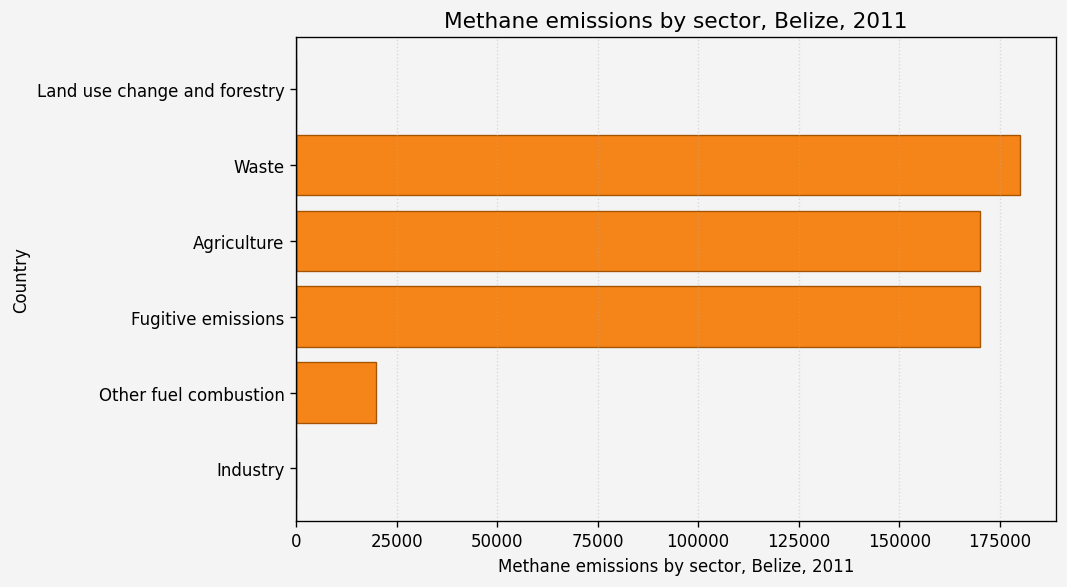


DEPLOT RAW OUTPUT:
TITLE | Methane emissions by sector, Belize, 2011<0x0A>Country | Methane emissions by sector<0x0A>Industry | 12.70<0x0A>Other fuel combustion | 1992.50<0x0A>Fugitive emissions | 17084.70<0x0A>Agriculture | 17063.30<0x0A>Waste | 17803.70<0x0A>Land use change and forestry | 22.40

PARSED DEPLOT ROWS:
[{"category": "Industry", "raw_values": ["12.70"], "numeric_values": [12.7]}, {"category": "Other fuel combustion", "raw_values": ["1992.50"], "numeric_values": [1992.5]}, {"category": "Fugitive emissions", "raw_values": ["17084.70"], "numeric_values": [17084.7]}, {"category": "Agriculture", "raw_values": ["17063.30"], "numeric_values": [17063.3]}, {"category": "Waste", "raw_values": ["17803.70"], "numeric_values": [17803.7]}, {"category": "Land use change and forestry", "raw_values": ["22.40"], "numeric_values": [22.4]}]

GROUND-TRUTH TABLE:
table columns: Country | Methane emissions by sector, Belize, 2011. row 1: Country = Land use change and forestry ; Methane emissio

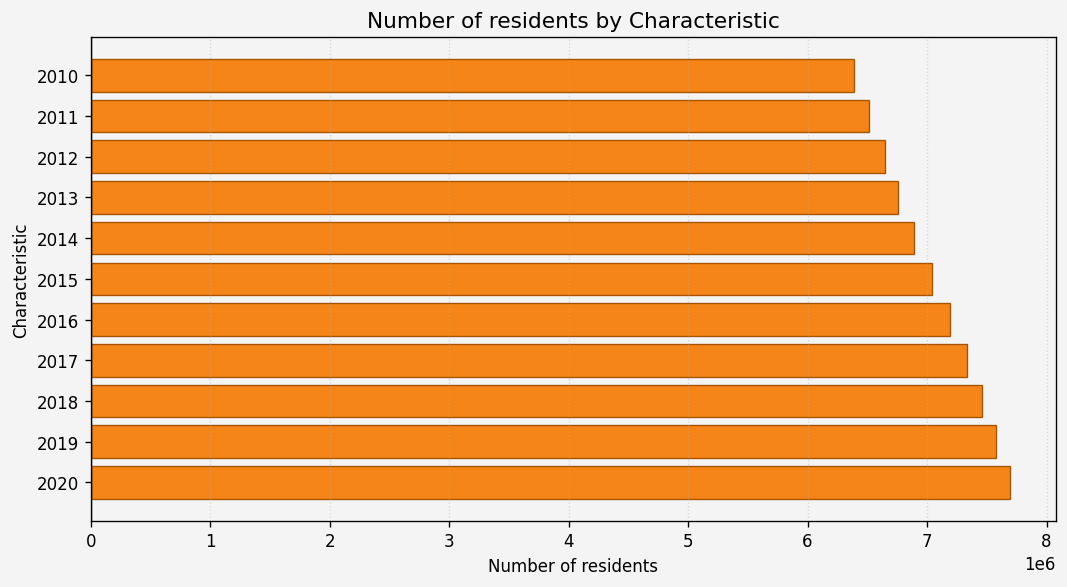


DEPLOT RAW OUTPUT:
TITLE | Number of residents by Characteristic | Characteristic <0x0A> Characteristic | Number of residents <0x0A> 2020 | 770 <0x0A> 2019 | 761 <0x0A> 2018 | 749 <0x0A> 2017 | 732 <0x0A> 2016 | 722 <0x0A> 2015 | 704 <0x0A> 2014 | 691 <0x0A> 2013 | 680 <0x0A> 2012 | 669 <0x0A> 2011 | 653 <0x0A> 2010 | 639

PARSED DEPLOT ROWS:
[{"category": "2020", "raw_values": ["770"], "numeric_values": [770.0]}, {"category": "2019", "raw_values": ["761"], "numeric_values": [761.0]}, {"category": "2018", "raw_values": ["749"], "numeric_values": [749.0]}, {"category": "2017", "raw_values": ["732"], "numeric_values": [732.0]}, {"category": "2016", "raw_values": ["722"], "numeric_values": [722.0]}, {"category": "2015", "raw_values": ["704"], "numeric_values": [704.0]}, {"category": "2014", "raw_values": ["691"], "numeric_values": [691.0]}, {"category": "2013", "raw_values": ["680"], "numeric_values": [680.0]}, {"category": "2012", "raw_values": ["669"], "numeric_values": [669.0]}, {"cat

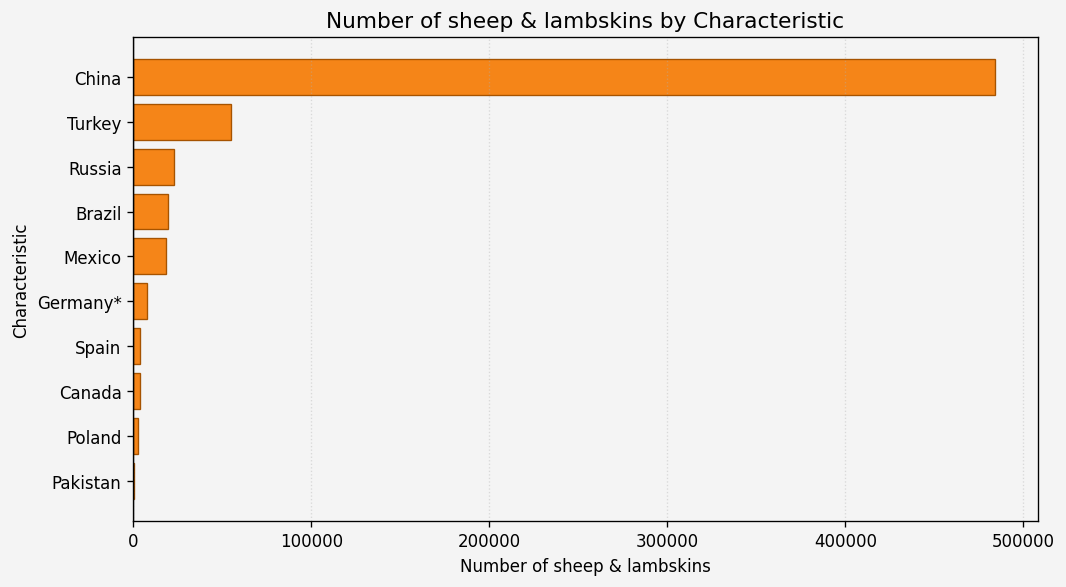


DEPLOT RAW OUTPUT:
TITLE | Number of sheep & lambskins by Characteristic <0x0A> Characteristic | Number of sheep & lambskins <0x0A> Pakistan | 162 <0x0A> Poland | 304 <0x0A> Canada | 445 <0x0A> Spain | 435 <0x0A> Germany* | 761 <0x0A> Mexico | 181 <0x0A> Brazil | 201 <0x0A> Russia | 228 <0x0A> Turkey | 561 <0x0A> China | 484

PARSED DEPLOT ROWS:
[{"category": "Pakistan", "raw_values": ["162"], "numeric_values": [162.0]}, {"category": "Poland", "raw_values": ["304"], "numeric_values": [304.0]}, {"category": "Canada", "raw_values": ["445"], "numeric_values": [445.0]}, {"category": "Spain", "raw_values": ["435"], "numeric_values": [435.0]}, {"category": "Germany*", "raw_values": ["761"], "numeric_values": [761.0]}, {"category": "Mexico", "raw_values": ["181"], "numeric_values": [181.0]}, {"category": "Brazil", "raw_values": ["201"], "numeric_values": [201.0]}, {"category": "Russia", "raw_values": ["228"], "numeric_values": [228.0]}, {"category": "Turkey", "raw_values": ["561"], "numeric_

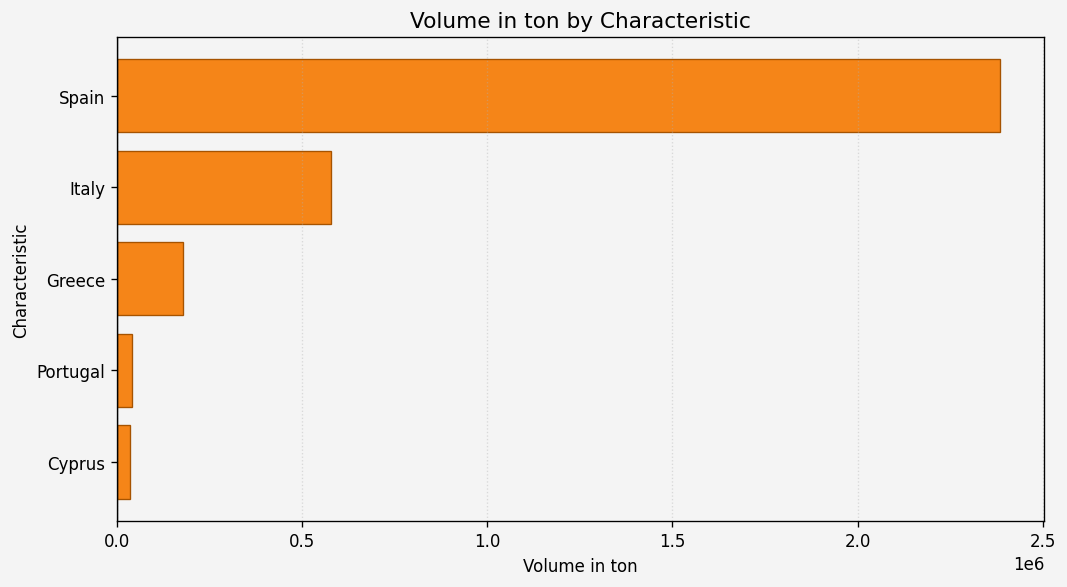


DEPLOT RAW OUTPUT:
TITLE | Volume in ton by Characteristic <0x0A> Characteristic | Volume in ton <0x0A> Cyprus | 350 <0x0A> Portugal | 370 <0x0A> Greece | 180 <0x0A> Italy | 580 <0x0A> Spain | 240

PARSED DEPLOT ROWS:
[{"category": "Cyprus", "raw_values": ["350"], "numeric_values": [350.0]}, {"category": "Portugal", "raw_values": ["370"], "numeric_values": [370.0]}, {"category": "Greece", "raw_values": ["180"], "numeric_values": [180.0]}, {"category": "Italy", "raw_values": ["580"], "numeric_values": [580.0]}, {"category": "Spain", "raw_values": ["240"], "numeric_values": [240.0]}]

GROUND-TRUTH TABLE:
table columns: Characteristic | Volume in ton. row 1: Characteristic = Spain ; Volume in ton = 2385000. row 2: Characteristic = Italy ; Volume in ton = 577000. row 3: Characteristic = Greece ; Volume in ton = 176881. row 4: Characteristic = Portugal ; Volume in ton = 40000. row 5: Characteristic = Cyprus ; Volume in ton = 35000.

CHART ID:
chartqa_train_12127__shuffled__vbar_blue

CHART

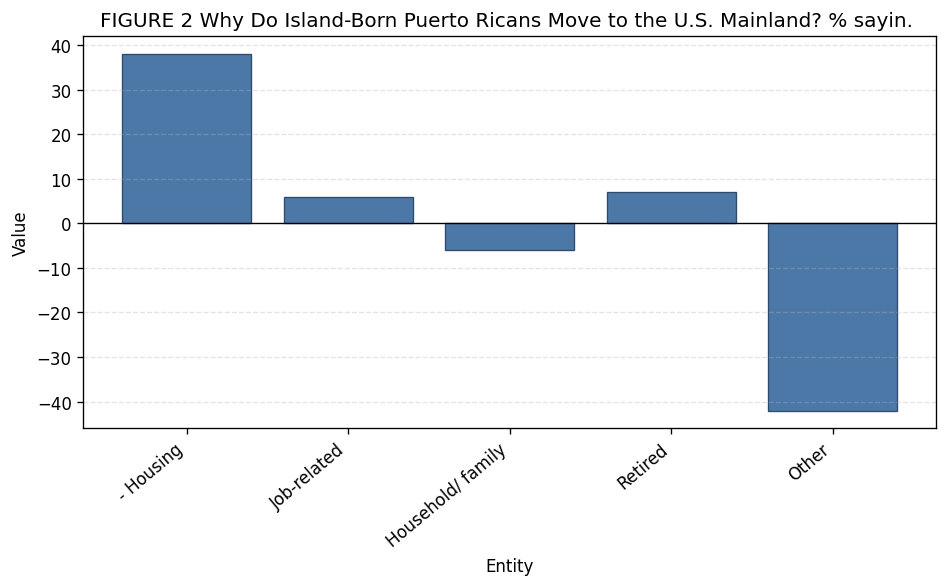


DEPLOT RAW OUTPUT:
TITLE | FIGURE 2 Why Do Island-Born Puerto Ricans Move to the U.S. Mainland? % sayin. <0x0A> Entity | Value <0x0A> - Housing | 38.450300 <0x0A> Job-related | 5.870310 <0x0A> Household/ family | 0.0181116 <0x0A> Retired | 7.834255 <0x0A> Other | 0.028368

PARSED DEPLOT ROWS:
[{"category": "- Housing", "raw_values": ["38.450300"], "numeric_values": [38.4503]}, {"category": "Job-related", "raw_values": ["5.870310"], "numeric_values": [5.87031]}, {"category": "Household/ family", "raw_values": ["0.0181116"], "numeric_values": [0.0181116]}, {"category": "Retired", "raw_values": ["7.834255"], "numeric_values": [7.834255]}, {"category": "Other", "raw_values": ["0.028368"], "numeric_values": [0.028368]}]

GROUND-TRUTH TABLE:
table columns: Entity | Value. row 1: Entity = - Housing ; Value = 38. row 2: Entity = Job-related ; Value = 6. row 3: Entity = Household/ family ; Value = -6. row 4: Entity = Retired ; Value = 7. row 5: Entity = Other ; Value = -42.


In [5]:
from IPython.display import display
from PIL import Image


# --------------------------------------------------
# Select five weakest numerical extractions
# --------------------------------------------------

verification_examples_df = (
    deplot_audit_metrics_df
    .sort_values(
        by=[
            "tolerant_value_recovery",
            "category_recovery_rate",
            "row_coverage"
        ],
        ascending=[
            True,
            True,
            True
        ]
    )
    .head(5)
)


# --------------------------------------------------
# Display image, extracted table and true table
# --------------------------------------------------

for _, example_row in (
    verification_examples_df.iterrows()
):

    print("\n" + "=" * 100)

    print("CHART ID:")
    print(example_row["chart_id"])

    print("\nCHART TYPE:")
    print(example_row["chart_type"])

    print("\nTABLE VARIANT:")
    print(example_row["table_variant_type"])

    print("\nMETRICS:")
    print(
        "Rows:",
        example_row["number_predicted_rows"],
        "/",
        example_row["number_ground_truth_rows"]
    )
    print(
        "Category recovery:",
        example_row[
            "category_recovery_rate"
        ]
    )
    print(
        "Tolerant value recovery:",
        example_row[
            "tolerant_value_recovery"
        ]
    )
    print(
        "Median relative error:",
        example_row[
            "median_relative_numeric_error"
        ]
    )

    image = (
        Image.open(
            example_row["image_path"]
        )
        .convert("RGB")
    )

    display(image)

    print("\nDEPLOT RAW OUTPUT:")
    print(example_row["deplot_raw_text"])

    print("\nPARSED DEPLOT ROWS:")
    print(example_row["parsed_rows_json"])

    print("\nGROUND-TRUTH TABLE:")
    print(example_row["ground_truth_table_text"])

    image.close()

In [2]:
from tqdm import tqdm


# --------------------------------------------------
# Restore full extraction progress
# --------------------------------------------------

if full_output_path.exists():

    existing_outputs_df = pd.read_parquet(
        full_output_path
    )

    full_results = (
        existing_outputs_df
        .to_dict(orient="records")
    )

    completed_chart_ids = set(
        existing_outputs_df[
            "chart_id"
        ].tolist()
    )

    print(
        "Resuming full extraction:",
        len(completed_chart_ids),
        "already completed"
    )

else:

    # Reuse the 100 charts already processed
    audit_seed_df = pd.read_parquet(
        audit_output_path
    )

    full_results = (
        audit_seed_df
        .to_dict(orient="records")
    )

    completed_chart_ids = set(
        audit_seed_df[
            "chart_id"
        ].tolist()
    )

    print(
        "Starting with audit outputs:",
        len(completed_chart_ids)
    )


# --------------------------------------------------
# Determine remaining charts
# --------------------------------------------------

remaining_full_df = (
    audit_source_df[
        ~audit_source_df["chart_id"].isin(
            completed_chart_ids
        )
    ]
    .reset_index(drop=True)
    .copy()
)

print("Total charts:", len(audit_source_df))
print("Already completed:", len(completed_chart_ids))
print("Remaining:", len(remaining_full_df))

missing_images = int(
    (
        ~remaining_full_df["image_path"]
        .apply(
            lambda path: Path(path).exists()
        )
    ).sum()
)

print("Missing images:", missing_images)

assert missing_images == 0


# --------------------------------------------------
# Safe checkpoint function
# --------------------------------------------------

temporary_output_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_full_outputs.tmp.parquet"
)


def save_full_checkpoint(records):

    checkpoint_df = (
        pd.DataFrame(records)
        .drop_duplicates(
            subset="chart_id",
            keep="last"
        )
        .reset_index(drop=True)
    )

    # Write to a temporary file first
    checkpoint_df.to_parquet(
        temporary_output_path,
        index=False
    )

    # Replace the main checkpoint only after
    # the temporary file was written successfully
    temporary_output_path.replace(
        full_output_path
    )

    return checkpoint_df


# --------------------------------------------------
# Run full extraction
# --------------------------------------------------

for newly_completed, (
    _,
    chart_row
) in enumerate(
    tqdm(
        remaining_full_df.iterrows(),
        total=len(remaining_full_df),
        desc="Full DePlot extraction"
    ),
    start=1
):

    try:
        extracted_table = (
            extract_table_with_deplot(
                chart_row["image_path"]
            )
        )

        extraction_status = "success"
        error_message = None

    except Exception as error:

        extracted_table = None
        extraction_status = "failed"
        error_message = str(error)

    full_results.append(
        {
            "chart_id": chart_row["chart_id"],
            "data_id": chart_row["data_id"],
            "source_data_id": (
                chart_row["source_data_id"]
            ),
            "split": chart_row["split"],
            "chart_type": chart_row["chart_type"],
            "style_id": chart_row["style_id"],
            "variant_type": (
                chart_row["variant_type"]
            ),
            "table_variant_type": (
                chart_row["table_variant_type"]
            ),
            "num_rows": int(
                chart_row["num_rows"]
            ),
            "image_path": chart_row["image_path"],
            "deplot_raw_text": extracted_table,
            "ground_truth_columns_json": (
                chart_row["columns_json"]
            ),
            "ground_truth_rows_json": (
                chart_row["rows_json"]
            ),
            "ground_truth_table_text": (
                chart_row[
                    "canonical_table_text"
                ]
            ),
            "extraction_status": (
                extraction_status
            ),
            "error_message": error_message
        }
    )

    # Save after every 20 new charts
    if (
        newly_completed % 20 == 0
        or newly_completed
        == len(remaining_full_df)
    ):
        save_full_checkpoint(
            full_results
        )


# --------------------------------------------------
# Final validation
# --------------------------------------------------

deplot_full_df = pd.read_parquet(
    full_output_path
)

print("\nFull extraction finished")
print("Rows saved:", len(deplot_full_df))
print(
    "Unique chart IDs:",
    deplot_full_df["chart_id"].nunique()
)

print("\nExtraction status")

display(
    deplot_full_df[
        "extraction_status"
    ]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\nCharts by type")

display(
    pd.crosstab(
        deplot_full_df["chart_type"],
        deplot_full_df[
            "extraction_status"
        ],
        margins=True
    )
)

print("\nCharts by variant")

display(
    pd.crosstab(
        deplot_full_df["variant_type"],
        deplot_full_df[
            "extraction_status"
        ],
        margins=True
    )
)

print("\nSaved:", full_output_path)

if (
    len(deplot_full_df) == 4104
    and deplot_full_df[
        "chart_id"
    ].nunique() == 4104
):
    print(
        "\nAll 4,104 charts were processed successfully."
    )
else:
    print(
        "\nExtraction is incomplete. "
        "Rerun this cell to resume."
    )

Starting with audit outputs: 100
Total charts: 4104
Already completed: 100
Remaining: 4004
Missing images: 0


Full DePlot extraction: 100%|██████████| 4004/4004 [2:37:57<00:00,  2.37s/it]  


Full extraction finished
Rows saved: 4104
Unique chart IDs: 4104

Extraction status


,count
extraction_status,
success,4104



Charts by type


extraction_status,success,All
chart_type,,
h_bar,700,700
line,1400,1400
pie,604,604
v_bar,1400,1400
All,4104,4104



Charts by variant


extraction_status,success,All
variant_type,,
anchor,700,700
hard_negative,1702,1702
hard_positive,1002,1002
positive,700,700
All,4104,4104



Saved: /home/pnola130/projects/chart_data_retrieval/data/derived/deplot/deplot_full_outputs.parquet

All 4,104 charts were processed successfully.


In [3]:
from pathlib import Path

import json
import numpy as np
import pandas as pd

from scipy.optimize import linear_sum_assignment
from tqdm import tqdm


# --------------------------------------------------
# Full DePlot output paths
# --------------------------------------------------

full_output_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_full_outputs.parquet"
)

full_metrics_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_full_metrics.parquet"
)

full_summary_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_full_summary.parquet"
)

full_summary_json_path = (
    DEPLOT_OUTPUT_DIR
    / "deplot_full_summary.json"
)


# --------------------------------------------------
# Load and validate completed extraction
# --------------------------------------------------

assert full_output_path.exists(), (
    "Full DePlot extraction file does not exist."
)

deplot_full_df = pd.read_parquet(
    full_output_path
)

print("Rows:", len(deplot_full_df))
print(
    "Unique charts:",
    deplot_full_df["chart_id"].nunique()
)

print("\nExtraction status:")

display(
    deplot_full_df[
        "extraction_status"
    ]
    .value_counts(dropna=False)
    .to_frame("count")
)

assert len(deplot_full_df) == 4104
assert (
    deplot_full_df["chart_id"].nunique()
    == 4104
)

print("\nFull extraction is ready for parsing.")

Rows: 4104
Unique charts: 4104

Extraction status:


,count
extraction_status,
success,4104



Full extraction is ready for parsing.


In [4]:
import math
import re
import unicodedata

from difflib import SequenceMatcher


# --------------------------------------------------
# General helpers
# --------------------------------------------------

def load_json_array(value):

    if isinstance(value, str):
        return json.loads(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, tuple):
        return list(value)

    if isinstance(value, list):
        return value

    return []


def normalize_label(value):

    if value is None:
        return ""

    text = unicodedata.normalize(
        "NFKD",
        str(value)
    )

    text = text.lower().strip()

    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text
    )

    return re.sub(
        r"\s+",
        " ",
        text
    ).strip()


def label_similarity(first, second):

    first = normalize_label(first)
    second = normalize_label(second)

    if not first and not second:
        return 1.0

    if not first or not second:
        return 0.0

    if first == second:
        return 1.0

    return SequenceMatcher(
        None,
        first,
        second
    ).ratio()


def parse_numeric(value):

    if value is None:
        return None

    text = str(value).strip()

    if not text:
        return None

    text = (
        text.replace("−", "-")
        .replace("–", "-")
        .replace("—", "-")
    )

    parenthesized_negative = (
        text.startswith("(")
        and text.endswith(")")
    )

    numeric_match = re.search(
        r"[-+]?"
        r"(?:\d{1,3}(?:,\d{3})+|\d+)"
        r"(?:\.\d+)?"
        r"(?:[eE][-+]?\d+)?",
        text
    )

    if numeric_match is None:
        return None

    numeric_text = (
        numeric_match.group(0)
        .replace(",", "")
    )

    try:
        number = float(numeric_text)
    except ValueError:
        return None

    if parenthesized_negative:
        number = -abs(number)

    suffix = text[
        numeric_match.end():
    ].strip().lower()

    if re.match(r"^(k|thousand)\b", suffix):
        number *= 1_000

    elif re.match(r"^(m|million)\b", suffix):
        number *= 1_000_000

    elif re.match(r"^(b|billion)\b", suffix):
        number *= 1_000_000_000

    return number


# --------------------------------------------------
# Parse one DePlot output
# --------------------------------------------------

def parse_deplot_output(raw_text):

    parsed = {
        "parse_success": False,
        "title": None,
        "header": [],
        "rows": [],
        "number_of_lines": 0
    }

    if raw_text is None:
        return parsed

    raw_text = str(raw_text).strip()

    if not raw_text:
        return parsed

    normalized_output = re.sub(
        r"<0x0a>",
        "\n",
        raw_text,
        flags=re.IGNORECASE
    )

    lines = [
        line.strip()
        for line in normalized_output.splitlines()
        if line.strip()
    ]

    parsed["number_of_lines"] = len(lines)

    header = []
    parsed_rows = []

    for line in lines:

        cells = [
            cell.strip()
            for cell in line.split("|")
        ]

        if len(cells) < 2:
            continue

        first_cell = normalize_label(
            cells[0]
        )

        if first_cell == "title":
            parsed["title"] = (
                " | ".join(cells[1:])
                .strip()
            )
            continue

        numeric_values = [
            parse_numeric(cell)
            for cell in cells[1:]
        ]

        has_numeric_value = any(
            value is not None
            for value in numeric_values
        )

        if has_numeric_value:

            parsed_rows.append(
                {
                    "category": cells[0],
                    "raw_values": cells[1:],
                    "numeric_values": (
                        numeric_values
                    )
                }
            )

        elif not header:

            header = cells

    parsed["header"] = header
    parsed["rows"] = parsed_rows
    parsed["parse_success"] = (
        len(parsed_rows) > 0
    )

    return parsed


# --------------------------------------------------
# Create E5-compatible text from DePlot output
# --------------------------------------------------

def serialize_parsed_deplot(parsed):

    rows = parsed["rows"]
    header = parsed["header"]
    title = parsed["title"]

    if header:
        category_column = header[0]

        value_columns = header[1:]
    else:
        category_column = "category"

        maximum_value_count = max(
            (
                len(row["raw_values"])
                for row in rows
            ),
            default=1
        )

        value_columns = [
            f"value {index + 1}"
            for index in range(
                maximum_value_count
            )
        ]

    text_parts = []

    if title:
        text_parts.append(
            f"title: {title}"
        )

    text_parts.append(
        "table columns: "
        + " | ".join(
            [category_column]
            + value_columns
        )
    )

    for row_number, row in enumerate(
        rows,
        start=1
    ):

        row_parts = [
            (
                f"{category_column} = "
                f"{row['category']}"
            )
        ]

        for value_index, raw_value in enumerate(
            row["raw_values"]
        ):

            if value_index < len(value_columns):
                value_column = value_columns[
                    value_index
                ]
            else:
                value_column = (
                    f"value {value_index + 1}"
                )

            row_parts.append(
                f"{value_column} = {raw_value}"
            )

        text_parts.append(
            f"row {row_number}: "
            + " ; ".join(row_parts)
        )

    return ". ".join(text_parts) + "."


# --------------------------------------------------
# Evaluate one parsed table
# --------------------------------------------------

CATEGORY_MATCH_THRESHOLD = 0.80
VALUE_ALIGNMENT_THRESHOLD = 0.50


def evaluate_deplot_table(
    parsed,
    ground_truth_columns_json,
    ground_truth_rows_json
):

    ground_truth_columns = load_json_array(
        ground_truth_columns_json
    )

    ground_truth_rows = load_json_array(
        ground_truth_rows_json
    )

    predicted_rows = parsed["rows"]

    number_gt_rows = len(
        ground_truth_rows
    )

    number_predicted_rows = len(
        predicted_rows
    )

    row_coverage = (
        min(
            number_predicted_rows,
            number_gt_rows
        )
        / number_gt_rows
        if number_gt_rows > 0
        else 0.0
    )

    exact_row_count = int(
        number_predicted_rows
        == number_gt_rows
    )

    ground_truth_categories = [
        row[0] if row else ""
        for row in ground_truth_rows
    ]

    predicted_categories = [
        row["category"]
        for row in predicted_rows
    ]

    similarity_matrix = np.zeros(
        (
            number_predicted_rows,
            number_gt_rows
        ),
        dtype=np.float32
    )

    for predicted_index, predicted_category in enumerate(
        predicted_categories
    ):

        for gt_index, gt_category in enumerate(
            ground_truth_categories
        ):

            similarity_matrix[
                predicted_index,
                gt_index
            ] = label_similarity(
                predicted_category,
                gt_category
            )

    matched_pairs = []

    if (
        number_predicted_rows > 0
        and number_gt_rows > 0
    ):

        predicted_assignment, gt_assignment = (
            linear_sum_assignment(
                -similarity_matrix
            )
        )

        for predicted_index, gt_index in zip(
            predicted_assignment,
            gt_assignment
        ):

            matched_pairs.append(
                {
                    "predicted_index": int(
                        predicted_index
                    ),
                    "ground_truth_index": int(
                        gt_index
                    ),
                    "category_similarity": float(
                        similarity_matrix[
                            predicted_index,
                            gt_index
                        ]
                    )
                }
            )

    category_similarity_sum = sum(
        pair["category_similarity"]
        for pair in matched_pairs
    )

    mean_category_similarity = (
        category_similarity_sum
        / number_gt_rows
        if number_gt_rows > 0
        else 0.0
    )

    recovered_categories = sum(
        pair["category_similarity"]
        >= CATEGORY_MATCH_THRESHOLD
        for pair in matched_pairs
    )

    category_recovery_rate = (
        recovered_categories
        / number_gt_rows
        if number_gt_rows > 0
        else 0.0
    )

    total_gt_values = sum(
        parse_numeric(value) is not None
        for row in ground_truth_rows
        for value in row[1:]
    )

    compared_values = 0
    strict_correct = 0
    tolerant_correct = 0

    absolute_errors = []
    relative_errors = []

    for pair in matched_pairs:

        if (
            pair["category_similarity"]
            < VALUE_ALIGNMENT_THRESHOLD
        ):
            continue

        predicted_row = predicted_rows[
            pair["predicted_index"]
        ]

        ground_truth_row = ground_truth_rows[
            pair["ground_truth_index"]
        ]

        predicted_values = (
            predicted_row["numeric_values"]
        )

        ground_truth_values = [
            parse_numeric(value)
            for value in ground_truth_row[1:]
        ]

        positions = min(
            len(predicted_values),
            len(ground_truth_values)
        )

        for value_index in range(positions):

            predicted_value = predicted_values[
                value_index
            ]

            ground_truth_value = ground_truth_values[
                value_index
            ]

            if (
                predicted_value is None
                or ground_truth_value is None
            ):
                continue

            compared_values += 1

            absolute_error = abs(
                predicted_value
                - ground_truth_value
            )

            relative_error = (
                absolute_error
                / max(
                    abs(ground_truth_value),
                    1.0
                )
            )

            absolute_errors.append(
                absolute_error
            )

            relative_errors.append(
                relative_error
            )

            strict_tolerance = max(
                0.05,
                0.01
                * abs(ground_truth_value)
            )

            tolerant_tolerance = max(
                0.20,
                0.05
                * abs(ground_truth_value)
            )

            if absolute_error <= strict_tolerance:
                strict_correct += 1

            if absolute_error <= tolerant_tolerance:
                tolerant_correct += 1

    if total_gt_values > 0:

        value_coverage = (
            compared_values
            / total_gt_values
        )

        strict_value_recovery = (
            strict_correct
            / total_gt_values
        )

        tolerant_value_recovery = (
            tolerant_correct
            / total_gt_values
        )

    else:

        value_coverage = 0.0
        strict_value_recovery = 0.0
        tolerant_value_recovery = 0.0

    expected_title = (
        ground_truth_columns[-1]
        if ground_truth_columns
        else ""
    )

    title_similarity = label_similarity(
        parsed["title"],
        expected_title
    )

    full_table_recovered = int(
        exact_row_count == 1
        and category_recovery_rate == 1.0
        and tolerant_value_recovery == 1.0
    )

    return {
        "parse_success": int(
            parsed["parse_success"]
        ),
        "number_ground_truth_rows": int(
            number_gt_rows
        ),
        "number_predicted_rows": int(
            number_predicted_rows
        ),
        "exact_row_count": exact_row_count,
        "row_coverage": float(
            row_coverage
        ),
        "mean_category_similarity": float(
            mean_category_similarity
        ),
        "category_recovery_rate": float(
            category_recovery_rate
        ),
        "value_coverage": float(
            value_coverage
        ),
        "strict_value_recovery": float(
            strict_value_recovery
        ),
        "tolerant_value_recovery": float(
            tolerant_value_recovery
        ),
        "mean_absolute_numeric_error": (
            float(np.mean(absolute_errors))
            if absolute_errors
            else np.nan
        ),
        "median_relative_numeric_error": (
            float(np.median(relative_errors))
            if relative_errors
            else np.nan
        ),
        "title_similarity": float(
            title_similarity
        ),
        "full_table_recovered": int(
            full_table_recovered
        ),
        "matched_pairs_json": json.dumps(
            matched_pairs
        )
    }


print("DePlot parser functions are ready.")


DePlot parser functions are ready.


In [5]:
# --------------------------------------------------
# Parse and evaluate all 4,104 charts
# --------------------------------------------------

full_evaluation_rows = []

for _, chart_row in tqdm(
    deplot_full_df.iterrows(),
    total=len(deplot_full_df),
    desc="Parsing full DePlot output"
):

    parsed = parse_deplot_output(
        chart_row["deplot_raw_text"]
    )

    metrics = evaluate_deplot_table(
        parsed,
        chart_row[
            "ground_truth_columns_json"
        ],
        chart_row[
            "ground_truth_rows_json"
        ]
    )

    deplot_table_text = (
        serialize_parsed_deplot(parsed)
    )

    full_evaluation_rows.append(
        {
            **chart_row.to_dict(),
            "parsed_title": (
                parsed["title"]
            ),
            "parsed_header_json": json.dumps(
                parsed["header"]
            ),
            "parsed_rows_json": json.dumps(
                parsed["rows"]
            ),
            "deplot_table_text": (
                deplot_table_text
            ),
            **metrics
        }
    )


deplot_full_metrics_df = pd.DataFrame(
    full_evaluation_rows
)

assert len(deplot_full_metrics_df) == 4104


# --------------------------------------------------
# Summary function
# --------------------------------------------------

def summarize_deplot_extraction(dataframe):

    return {
        "number_of_charts": int(
            len(dataframe)
        ),
        "parse_success_rate": float(
            dataframe[
                "parse_success"
            ].mean()
        ),
        "exact_row_count_rate": float(
            dataframe[
                "exact_row_count"
            ].mean()
        ),
        "mean_row_coverage": float(
            dataframe[
                "row_coverage"
            ].mean()
        ),
        "mean_category_similarity": float(
            dataframe[
                "mean_category_similarity"
            ].mean()
        ),
        "mean_category_recovery": float(
            dataframe[
                "category_recovery_rate"
            ].mean()
        ),
        "mean_value_coverage": float(
            dataframe[
                "value_coverage"
            ].mean()
        ),
        "strict_value_recovery": float(
            dataframe[
                "strict_value_recovery"
            ].mean()
        ),
        "tolerant_value_recovery": float(
            dataframe[
                "tolerant_value_recovery"
            ].mean()
        ),
        "median_relative_numeric_error": float(
            dataframe[
                "median_relative_numeric_error"
            ].median()
        ),
        "mean_title_similarity": float(
            dataframe[
                "title_similarity"
            ].mean()
        ),
        "full_table_recovery_rate": float(
            dataframe[
                "full_table_recovered"
            ].mean()
        )
    }


# --------------------------------------------------
# Overall and grouped summaries
# --------------------------------------------------

summary_rows = [
    {
        "group": "overall",
        **summarize_deplot_extraction(
            deplot_full_metrics_df
        )
    }
]

grouping_definitions = [
    ("split", "split"),
    ("chart_type", "chart_type"),
    ("chart_variant", "variant_type"),
    (
        "table_variant",
        "table_variant_type"
    )
]

for group_prefix, column_name in (
    grouping_definitions
):

    for group_value, group_df in (
        deplot_full_metrics_df.groupby(
            column_name,
            sort=False
        )
    ):

        summary_rows.append(
            {
                "group": (
                    f"{group_prefix}="
                    f"{group_value}"
                ),
                **summarize_deplot_extraction(
                    group_df
                )
            }
        )


deplot_full_summary_df = (
    pd.DataFrame(summary_rows)
    .set_index("group")
)


# --------------------------------------------------
# Save before displaying
# --------------------------------------------------

deplot_full_metrics_df.to_parquet(
    full_metrics_path,
    index=False
)

deplot_full_summary_df.to_parquet(
    full_summary_path
)

summary_json_data = json.loads(
    deplot_full_summary_df.to_json(
        orient="index"
    )
)

with open(
    full_summary_json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary_json_data,
        file,
        indent=2
    )


# --------------------------------------------------
# Display final summary
# --------------------------------------------------

print("Full DePlot extraction metrics")

display(
    deplot_full_summary_df.round(4)
)


# --------------------------------------------------
# Display weakest examples
# --------------------------------------------------

weakest_columns = [
    "chart_id",
    "chart_type",
    "variant_type",
    "table_variant_type",
    "number_ground_truth_rows",
    "number_predicted_rows",
    "category_recovery_rate",
    "tolerant_value_recovery",
    "median_relative_numeric_error",
    "deplot_raw_text",
    "ground_truth_table_text"
]

print("\nTwenty weakest full-benchmark examples")

display(
    deplot_full_metrics_df
    .sort_values(
        by=[
            "tolerant_value_recovery",
            "category_recovery_rate",
            "row_coverage"
        ],
        ascending=[
            True,
            True,
            True
        ]
    )
    [weakest_columns]
    .head(20)
)


print("\nSaved files:")

for saved_path in [
    full_metrics_path,
    full_summary_path,
    full_summary_json_path
]:
    print(
        saved_path.name,
        ":",
        saved_path.exists()
    )

Parsing full DePlot output: 100%|██████████| 4104/4104 [00:06<00:00, 682.55it/s]


Full DePlot extraction metrics


,number_of_charts,parse_success_rate,exact_row_count_rate,mean_row_coverage,mean_category_similarity,mean_category_recovery,mean_value_coverage,strict_value_recovery,tolerant_value_recovery,median_relative_numeric_error,mean_title_similarity,full_table_recovery_rate
group,,,,,,,,,,,,
overall,4104,0.9995,0.7970,0.9915,0.9828,0.9788,0.9829,0.7846,0.8858,0.0031,0.6177,0.6165
split=train,2918,0.9993,0.7838,0.9909,0.9818,0.9775,0.9821,0.7799,0.8819,0.0032,0.6053,0.6021
split=val,592,1.0000,0.8429,0.9951,0.9897,0.9881,0.9898,0.8250,0.9012,0.0031,0.6523,0.6875
split=test,594,1.0000,0.8165,0.9909,0.9805,0.9756,0.9801,0.7676,0.8896,0.0031,0.6440,0.6162
chart_type=pie,604,1.0000,0.7517,0.9812,0.9541,0.9382,0.9532,0.9026,0.9058,0.0000,0.6285,0.6573
chart_type=line,1400,1.0000,0.8271,0.9988,0.9934,0.9911,0.9938,0.7952,0.8886,0.0026,0.6139,0.6357
chart_type=h_bar,700,1.0000,0.6900,0.9726,0.9703,0.9696,0.9706,0.7905,0.8940,0.0031,0.6507,0.5729
chart_type=v_bar,1400,0.9986,0.8400,0.9981,0.9908,0.9886,0.9911,0.7203,0.8703,0.0053,0.6003,0.6014
chart_variant=hard_positive,1002,1.0000,0.8024,0.9934,0.9806,0.9741,0.9809,0.8304,0.8971,0.0014,0.6090,0.6407



Twenty weakest full-benchmark examples


,chart_id,chart_type,variant_type,table_variant_type,number_ground_truth_rows,number_predicted_rows,category_recovery_rate,tolerant_value_recovery,median_relative_numeric_error,deplot_raw_text,ground_truth_table_text
1000,chartqa_train_two_col_101557__vbar_blue,v_bar,anchor,original,14,0,0.000000,0.0,NaN,TITLE | Domestic demand in metric tons by Char...,table columns: Characteristic | Domestic deman...
1002,chartqa_train_two_col_101557__shuffled__vbar_blue,v_bar,hard_negative,hard_negative,14,0,0.000000,0.0,NaN,TITLE | Domestic demand in metric tons by Char...,table columns: Characteristic | Domestic deman...
2618,chartqa_train_two_col_21932__shuffled__pie_pal...,pie,hard_negative,hard_negative,5,30,0.000000,0.0,195895.755430,TITLE | Number of complaints by Characteristic...,table columns: Characteristic | Number of comp...
3392,chartqa_train_11993__pie_palette,pie,hard_positive,original,3,3,0.000000,0.0,NaN,TITLE | Views of Job Availability Availability...,table columns: Entity | Value. row 1: Entity =...
3851,chartqa_test_42902375003200__shuffled__pie_pal...,pie,hard_negative,hard_negative,3,3,0.333333,0.0,1.000000,TITLE | Annual CO<0xE2><0x82><0x82> emissions ...,table columns: Country | Annual CO₂ emissions ...
603,chartqa_train_859__hbar_orange,h_bar,positive,original,3,2,0.666667,0.0,0.899466,TITLE | <0x0A> Entity | Values <0x0A> Rep/Lea...,table columns: Entity | Values. row 1: Entity ...
3265,chartqa_train_two_col_22006__pie_palette,pie,hard_positive,original,4,4,0.750000,0.0,0.990058,TITLE | EBITDA margin by Characteristic <0x0A>...,table columns: Characteristic | EBITDA margin....
3787,chartqa_val_two_col_20108__shuffled__line_green,line,hard_negative,hard_negative,4,4,0.750000,0.0,0.900085,TITLE | Revenue in million U.S. dollars by Cha...,table columns: Characteristic | Revenue in mil...
1780,chartqa_val_two_col_100643__hbar_orange,h_bar,positive,original,15,12,0.800000,0.0,0.999999,TITLE | Number of registered cars by Character...,table columns: Characteristic | Number of regi...
1219,chartqa_train_two_col_4176__shuffled__vbar_blue,v_bar,hard_negative,hard_negative,10,10,0.800000,0.0,0.583936,TITLE | Endowment (in million U.S. dollars) by...,table columns: Characteristic | Endowment (in ...



Saved files:
deplot_full_metrics.parquet : True
deplot_full_summary.parquet : True
deplot_full_summary.json : True


In [7]:
from pathlib import Path

import json
import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer
from tqdm import tqdm


# --------------------------------------------------
# Restore paths
# --------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

DEPLOT_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "deplot"
)

MODEL_CACHE_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "model_cache"
)

DEPLOT_E5_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "deplot_e5_base_v2"
)

ORACLE_E5_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "oracle_e5_base_v2"
)

DEPLOT_E5_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# Reload DePlot metrics
# --------------------------------------------------

deplot_metrics_path = (
    DEPLOT_DATA_DIR
    / "deplot_full_metrics.parquet"
)

assert deplot_metrics_path.exists()

deplot_charts_df = pd.read_parquet(
    deplot_metrics_path
)

assert len(deplot_charts_df) == 4104

print(
    "DePlot charts restored:",
    len(deplot_charts_df)
)


# --------------------------------------------------
# Reload query embeddings and metadata
# --------------------------------------------------

query_embeddings = np.load(
    ORACLE_E5_DIR
    / "query_embeddings.npy"
)

query_metadata_df = pd.read_parquet(
    ORACLE_E5_DIR
    / "query_metadata.parquet"
)

print(
    "Query embeddings restored:",
    query_embeddings.shape
)


# --------------------------------------------------
# Reload E5
# --------------------------------------------------

MODEL_NAME = "intfloat/e5-base-v2"

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

assert device == "cuda"

print("GPU:", torch.cuda.get_device_name(0))

e5_model = SentenceTransformer(
    MODEL_NAME,
    device=device,
    cache_folder=str(MODEL_CACHE_DIR)
)

e5_model.max_seq_length = 512
e5_tokenizer = e5_model.tokenizer

print(
    "E5 restored:",
    e5_model.get_sentence_embedding_dimension()
)

print("Restoration completed.")

DePlot charts restored: 4104
Query embeddings restored: (986, 768)
GPU: NVIDIA A100-SXM4-80GB
E5 restored: 768
Restoration completed.


In [8]:
import json

import numpy as np
import pandas as pd
import torch

from tqdm import tqdm


# --------------------------------------------------
# Chunking helpers
# --------------------------------------------------

MAX_E5_TOKENS = 512


def load_json_value(value, default):

    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return default

    if isinstance(value, list):
        return value

    return default


def get_token_count(text):
    return (
        len(
            e5_tokenizer.tokenize(text)
        )
        + 2
    )


def truncate_text_to_e5_limit(text):

    encoded = e5_tokenizer(
        text,
        max_length=MAX_E5_TOKENS,
        truncation=True,
        add_special_tokens=True
    )

    return e5_tokenizer.decode(
        encoded["input_ids"],
        skip_special_tokens=True
    )


def create_deplot_chunks(chart_row):

    title = chart_row.get(
        "parsed_title",
        None
    )

    header = load_json_value(
        chart_row.get(
            "parsed_header_json",
            "[]"
        ),
        []
    )

    parsed_rows = load_json_value(
        chart_row.get(
            "parsed_rows_json",
            "[]"
        ),
        []
    )

    if header:
        category_column = str(header[0])

        value_columns = [
            str(value)
            for value in header[1:]
        ]
    else:
        category_column = "category"

        maximum_value_count = max(
            (
                len(
                    row.get(
                        "raw_values",
                        []
                    )
                )
                for row in parsed_rows
            ),
            default=1
        )

        value_columns = [
            f"value {index + 1}"
            for index in range(
                maximum_value_count
            )
        ]

    base_parts = []

    if title:
        base_parts.append(
            f"title: {title}"
        )

    base_parts.append(
        "table columns: "
        + " | ".join(
            [category_column]
            + value_columns
        )
    )

    base_text = ". ".join(base_parts)

    serialized_rows = []

    for row_number, parsed_row in enumerate(
        parsed_rows,
        start=1
    ):

        category = parsed_row.get(
            "category",
            ""
        )

        raw_values = parsed_row.get(
            "raw_values",
            []
        )

        row_parts = [
            f"{category_column} = {category}"
        ]

        for value_index, raw_value in enumerate(
            raw_values
        ):

            if value_index < len(value_columns):
                value_column = value_columns[
                    value_index
                ]
            else:
                value_column = (
                    f"value {value_index + 1}"
                )

            row_parts.append(
                f"{value_column} = {raw_value}"
            )

        serialized_rows.append(
            f"row {row_number}: "
            + " ; ".join(row_parts)
        )

    # Handle outputs with no parseable rows.
    if not serialized_rows:

        passage_text = (
            "passage: "
            + base_text
            + "."
        )

        if (
            get_token_count(passage_text)
            > MAX_E5_TOKENS
        ):
            passage_text = (
                truncate_text_to_e5_limit(
                    passage_text
                )
            )

        return [
            {
                "chunk_text": passage_text,
                "row_start": None,
                "row_end": None,
                "was_truncated": False
            }
        ]

    chunks = []
    current_rows = []
    current_start = 1

    for row_position, row_text in enumerate(
        serialized_rows,
        start=1
    ):

        proposed_rows = (
            current_rows
            + [row_text]
        )

        proposed_text = (
            "passage: "
            + base_text
            + ". "
            + ". ".join(proposed_rows)
            + "."
        )

        if (
            get_token_count(proposed_text)
            <= MAX_E5_TOKENS
        ):

            current_rows = proposed_rows

        else:

            if current_rows:

                completed_text = (
                    "passage: "
                    + base_text
                    + ". "
                    + ". ".join(current_rows)
                    + "."
                )

                chunks.append(
                    {
                        "chunk_text": completed_text,
                        "row_start": (
                            current_start
                        ),
                        "row_end": (
                            row_position - 1
                        ),
                        "was_truncated": False
                    }
                )

                current_rows = [row_text]
                current_start = row_position

            else:

                # Extremely long individual row.
                single_row_text = (
                    "passage: "
                    + base_text
                    + ". "
                    + row_text
                    + "."
                )

                truncated_text = (
                    truncate_text_to_e5_limit(
                        single_row_text
                    )
                )

                chunks.append(
                    {
                        "chunk_text": truncated_text,
                        "row_start": (
                            row_position
                        ),
                        "row_end": (
                            row_position
                        ),
                        "was_truncated": True
                    }
                )

                current_rows = []
                current_start = (
                    row_position + 1
                )

    if current_rows:

        completed_text = (
            "passage: "
            + base_text
            + ". "
            + ". ".join(current_rows)
            + "."
        )

        chunks.append(
            {
                "chunk_text": completed_text,
                "row_start": current_start,
                "row_end": len(
                    serialized_rows
                ),
                "was_truncated": False
            }
        )

    return chunks


# --------------------------------------------------
# Build chunks for all charts
# --------------------------------------------------

deplot_charts_df = (
    deplot_charts_df
    .reset_index(drop=True)
    .copy()
)

deplot_charts_df["embedding_index"] = np.arange(
    len(deplot_charts_df)
)

chunk_records = []

for chart_index, chart_row in tqdm(
    deplot_charts_df.iterrows(),
    total=len(deplot_charts_df),
    desc="Creating row-aware chunks"
):

    chart_chunks = create_deplot_chunks(
        chart_row
    )

    for chunk_number, chunk in enumerate(
        chart_chunks
    ):

        chunk_records.append(
            {
                "chart_id": (
                    chart_row["chart_id"]
                ),
                "chart_embedding_index": int(
                    chart_index
                ),
                "chunk_number": int(
                    chunk_number
                ),
                "row_start": (
                    chunk["row_start"]
                ),
                "row_end": (
                    chunk["row_end"]
                ),
                "was_truncated": (
                    chunk["was_truncated"]
                ),
                "chunk_text": (
                    chunk["chunk_text"]
                )
            }
        )


chunk_metadata_df = pd.DataFrame(
    chunk_records
)

chunk_metadata_df["token_count"] = (
    chunk_metadata_df[
        "chunk_text"
    ].apply(get_token_count)
)


# --------------------------------------------------
# Validate chunking
# --------------------------------------------------

print("Charts:", len(deplot_charts_df))
print("Chunks:", len(chunk_metadata_df))

print(
    "Charts with multiple chunks:",
    chunk_metadata_df.groupby(
        "chart_id"
    ).size().gt(1).sum()
)

print(
    "Maximum chunk tokens:",
    chunk_metadata_df[
        "token_count"
    ].max()
)

print(
    "Individually truncated rows:",
    chunk_metadata_df[
        "was_truncated"
    ].sum()
)

assert (
    chunk_metadata_df[
        "token_count"
    ].max()
    <= MAX_E5_TOKENS
)

assert (
    chunk_metadata_df[
        "chart_id"
    ].nunique()
    == 4104
)


# --------------------------------------------------
# Encode all chunks
# --------------------------------------------------

chunk_texts = (
    chunk_metadata_df[
        "chunk_text"
    ]
    .tolist()
)

e5_model.eval()

with torch.inference_mode():

    chunk_embeddings = e5_model.encode(
        chunk_texts,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

chunk_embeddings = chunk_embeddings.astype(
    np.float32
)

print(
    "Chunk embeddings:",
    chunk_embeddings.shape
)


# --------------------------------------------------
# Aggregate chunks into one vector per chart
# --------------------------------------------------

deplot_chart_embeddings = np.zeros(
    (
        len(deplot_charts_df),
        chunk_embeddings.shape[1]
    ),
    dtype=np.float32
)

for chart_embedding_index, group_df in (
    chunk_metadata_df.groupby(
        "chart_embedding_index",
        sort=False
    )
):

    chunk_indices = group_df.index.to_numpy()

    combined_embedding = (
        chunk_embeddings[
            chunk_indices
        ].mean(axis=0)
    )

    combined_norm = np.linalg.norm(
        combined_embedding
    )

    if combined_norm > 0:
        combined_embedding = (
            combined_embedding
            / combined_norm
        )

    deplot_chart_embeddings[
        int(chart_embedding_index)
    ] = combined_embedding


# --------------------------------------------------
# Validate final embeddings
# --------------------------------------------------

embedding_norms = np.linalg.norm(
    deplot_chart_embeddings,
    axis=1
)

print(
    "Chart embeddings:",
    deplot_chart_embeddings.shape
)

print(
    "Mean chart norm:",
    round(
        float(
            embedding_norms.mean()
        ),
        6
    )
)

print(
    "Minimum chart norm:",
    round(
        float(
            embedding_norms.min()
        ),
        6
    )
)


# --------------------------------------------------
# Save embeddings and metadata
# --------------------------------------------------

chart_embeddings_path = (
    DEPLOT_E5_DIR
    / "chart_embeddings.npy"
)

chart_metadata_path = (
    DEPLOT_E5_DIR
    / "chart_metadata.parquet"
)

chunk_embeddings_path = (
    DEPLOT_E5_DIR
    / "chunk_embeddings.npy"
)

chunk_metadata_path = (
    DEPLOT_E5_DIR
    / "chunk_metadata.parquet"
)

embedding_config_path = (
    DEPLOT_E5_DIR
    / "embedding_config.json"
)

np.save(
    chart_embeddings_path,
    deplot_chart_embeddings
)

np.save(
    chunk_embeddings_path,
    chunk_embeddings
)

deplot_charts_df.to_parquet(
    chart_metadata_path,
    index=False
)

chunk_metadata_df.to_parquet(
    chunk_metadata_path,
    index=False
)

embedding_config = {
    "model_name": MODEL_NAME,
    "embedding_dimension": int(
        deplot_chart_embeddings.shape[1]
    ),
    "maximum_sequence_length": (
        MAX_E5_TOKENS
    ),
    "number_of_charts": int(
        len(deplot_charts_df)
    ),
    "number_of_chunks": int(
        len(chunk_metadata_df)
    ),
    "charts_with_multiple_chunks": int(
        chunk_metadata_df.groupby(
            "chart_id"
        ).size().gt(1).sum()
    ),
    "aggregation": (
        "mean of normalized chunk embeddings, "
        "then L2 normalization"
    )
}

with open(
    embedding_config_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        embedding_config,
        file,
        indent=2
    )


print("\nSaved files:")

for file_path in [
    chart_embeddings_path,
    chart_metadata_path,
    chunk_embeddings_path,
    chunk_metadata_path,
    embedding_config_path
]:
    print(
        file_path.name,
        ":",
        file_path.exists()
    )

Creating row-aware chunks: 100%|██████████| 4104/4104 [00:08<00:00, 507.67it/s]


Charts: 4104
Chunks: 4151
Charts with multiple chunks: 47
Maximum chunk tokens: 512
Individually truncated rows: 0


Batches:   0%|          | 0/65 [00:00<?, ?it/s]

Chunk embeddings: (4151, 768)
Chart embeddings: (4104, 768)
Mean chart norm: 1.0
Minimum chart norm: 1.0

Saved files:
chart_embeddings.npy : True
chart_metadata.parquet : True
chunk_embeddings.npy : True
chunk_metadata.parquet : True
embedding_config.json : True


In [9]:
import json

import numpy as np
import pandas as pd


# --------------------------------------------------
# Paths
# --------------------------------------------------

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# Restore embeddings if necessary
# --------------------------------------------------

if "deplot_chart_embeddings" not in globals():

    deplot_chart_embeddings = np.load(
        DEPLOT_E5_DIR
        / "chart_embeddings.npy"
    )

if "deplot_charts_df" not in globals():

    deplot_charts_df = pd.read_parquet(
        DEPLOT_E5_DIR
        / "chart_metadata.parquet"
    )

if "query_embeddings" not in globals():

    query_embeddings = np.load(
        ORACLE_E5_DIR
        / "query_embeddings.npy"
    )

if "query_metadata_df" not in globals():

    query_metadata_df = pd.read_parquet(
        ORACLE_E5_DIR
        / "query_metadata.parquet"
    )


# --------------------------------------------------
# Helper functions
# --------------------------------------------------

def parse_id_list(value):

    if isinstance(value, str):
        return json.loads(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, list):
        return value

    if isinstance(value, tuple):
        return list(value)

    return []


def calculate_ndcg_at_k(
    ranked_ids,
    positive_ids,
    k=10
):

    positive_ids = set(positive_ids)

    relevance = np.array(
        [
            1.0
            if item_id in positive_ids
            else 0.0
            for item_id in ranked_ids[:k]
        ],
        dtype=np.float32
    )

    discounts = 1.0 / np.log2(
        np.arange(
            2,
            len(relevance) + 2
        )
    )

    dcg = float(
        np.sum(
            relevance * discounts
        )
    )

    ideal_positive_count = min(
        len(positive_ids),
        k
    )

    if ideal_positive_count == 0:
        return 0.0

    idcg = float(
        np.sum(
            discounts[
                :ideal_positive_count
            ]
        )
    )

    return dcg / idcg


def summarize_query_chart(dataframe):

    return {
        "number_of_queries": int(
            len(dataframe)
        ),
        "recall_at_1": float(
            dataframe[
                "recall_at_1"
            ].mean()
        ),
        "recall_at_5": float(
            dataframe[
                "recall_at_5"
            ].mean()
        ),
        "recall_at_10": float(
            dataframe[
                "recall_at_10"
            ].mean()
        ),
        "mrr": float(
            dataframe[
                "reciprocal_rank"
            ].mean()
        ),
        "ndcg_at_10": float(
            dataframe[
                "ndcg_at_10"
            ].mean()
        ),
        "median_first_positive_rank": float(
            dataframe[
                "first_positive_rank"
            ].median()
        ),
        "mean_positive_similarity": float(
            dataframe[
                "mean_positive_similarity"
            ].mean()
        ),
        "mean_counterfactual_similarity": float(
            dataframe[
                "mean_counterfactual_similarity"
            ].mean()
        ),
        "mean_query_data_gap": float(
            dataframe[
                "query_data_gap"
            ].mean()
        ),
        "counterfactual_outrank_rate": float(
            dataframe[
                "counterfactual_outranks"
            ].mean()
        )
    }


# --------------------------------------------------
# Validate embedding order
# --------------------------------------------------

deplot_charts_df = (
    deplot_charts_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

query_metadata_df = (
    query_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

assert (
    len(deplot_charts_df)
    == len(deplot_chart_embeddings)
    == 4104
)

assert (
    len(query_metadata_df)
    == len(query_embeddings)
    == 986
)


# --------------------------------------------------
# Evaluate query→chart by split
# --------------------------------------------------

query_chart_rows = []

for split_name in [
    "train",
    "val",
    "test"
]:

    candidate_df = (
        deplot_charts_df[
            deplot_charts_df["split"]
            == split_name
        ]
        .reset_index(drop=True)
    )

    split_queries_df = (
        query_metadata_df[
            query_metadata_df["split"]
            == split_name
        ]
        .reset_index(drop=True)
    )

    candidate_ids = (
        candidate_df["chart_id"]
        .astype(str)
        .to_numpy()
    )

    candidate_embedding_indices = (
        candidate_df[
            "embedding_index"
        ]
        .astype(int)
        .to_numpy()
    )

    candidate_embeddings = (
        deplot_chart_embeddings[
            candidate_embedding_indices
        ]
    )

    candidate_id_set = set(
        candidate_ids.tolist()
    )

    local_index_by_id = {
        chart_id: local_index
        for local_index, chart_id
        in enumerate(candidate_ids)
    }

    print(
        f"{split_name}:",
        len(split_queries_df),
        "queries,",
        len(candidate_df),
        "candidate charts"
    )

    for _, query_row in (
        split_queries_df.iterrows()
    ):

        query_index = int(
            query_row[
                "embedding_index"
            ]
        )

        query_vector = query_embeddings[
            query_index
        ]

        similarities = (
            candidate_embeddings
            @ query_vector
        )

        ranking_order = np.argsort(
            -similarities,
            kind="stable"
        )

        ranked_ids = candidate_ids[
            ranking_order
        ]

        positive_ids = [
            chart_id
            for chart_id in parse_id_list(
                query_row[
                    "positive_chart_ids_json"
                ]
            )
            if chart_id in candidate_id_set
        ]

        counterfactual_ids = [
            chart_id
            for chart_id in parse_id_list(
                query_row[
                    "counterfactual_chart_ids_json"
                ]
            )
            if chart_id in candidate_id_set
        ]

        assert len(positive_ids) > 0

        positive_id_set = set(
            positive_ids
        )

        positive_ranks = [
            rank
            for rank, chart_id in enumerate(
                ranked_ids,
                start=1
            )
            if chart_id in positive_id_set
        ]

        first_positive_rank = min(
            positive_ranks
        )

        positive_similarities = np.array(
            [
                similarities[
                    local_index_by_id[
                        chart_id
                    ]
                ]
                for chart_id in positive_ids
            ],
            dtype=np.float32
        )

        counterfactual_similarities = np.array(
            [
                similarities[
                    local_index_by_id[
                        chart_id
                    ]
                ]
                for chart_id
                in counterfactual_ids
            ],
            dtype=np.float32
        )

        mean_positive_similarity = float(
            positive_similarities.mean()
        )

        best_positive_similarity = float(
            positive_similarities.max()
        )

        if len(counterfactual_similarities) > 0:

            mean_counterfactual_similarity = float(
                counterfactual_similarities.mean()
            )

            best_counterfactual_similarity = float(
                counterfactual_similarities.max()
            )

            query_data_gap = (
                mean_positive_similarity
                - mean_counterfactual_similarity
            )

            counterfactual_outranks = int(
                best_counterfactual_similarity
                > best_positive_similarity
            )

        else:

            mean_counterfactual_similarity = np.nan
            best_counterfactual_similarity = np.nan
            query_data_gap = np.nan
            counterfactual_outranks = 0

        query_chart_rows.append(
            {
                "query_id": (
                    query_row["query_id"]
                ),
                "split": split_name,
                "question": (
                    query_row["question"]
                ),
                "answer": (
                    query_row["answer"]
                ),
                "question_source": (
                    query_row[
                        "question_source"
                    ]
                ),
                "candidate_pool_size": int(
                    len(candidate_ids)
                ),
                "number_of_positives": int(
                    len(positive_ids)
                ),
                "number_of_counterfactuals": int(
                    len(counterfactual_ids)
                ),
                "first_positive_rank": int(
                    first_positive_rank
                ),
                "recall_at_1": int(
                    first_positive_rank <= 1
                ),
                "recall_at_5": int(
                    first_positive_rank <= 5
                ),
                "recall_at_10": int(
                    first_positive_rank <= 10
                ),
                "reciprocal_rank": float(
                    1.0
                    / first_positive_rank
                ),
                "ndcg_at_10": (
                    calculate_ndcg_at_k(
                        ranked_ids,
                        positive_ids,
                        k=10
                    )
                ),
                "mean_positive_similarity": (
                    mean_positive_similarity
                ),
                "mean_counterfactual_similarity": (
                    mean_counterfactual_similarity
                ),
                "best_positive_similarity": (
                    best_positive_similarity
                ),
                "best_counterfactual_similarity": (
                    best_counterfactual_similarity
                ),
                "query_data_gap": float(
                    query_data_gap
                ),
                "counterfactual_outranks": int(
                    counterfactual_outranks
                )
            }
        )


# --------------------------------------------------
# Summarize and save
# --------------------------------------------------

deplot_e5_query_chart_results_df = (
    pd.DataFrame(query_chart_rows)
)

assert (
    len(deplot_e5_query_chart_results_df)
    == 986
)

summary_rows = [
    {
        "group": "overall",
        **summarize_query_chart(
            deplot_e5_query_chart_results_df
        )
    }
]

for split_name, split_df in (
    deplot_e5_query_chart_results_df.groupby(
        "split",
        sort=False
    )
):

    summary_rows.append(
        {
            "group": split_name,
            **summarize_query_chart(
                split_df
            )
        }
    )

deplot_e5_query_chart_metrics_df = (
    pd.DataFrame(summary_rows)
    .set_index("group")
)

print("\nDePlot+E5 query→chart metrics")

display(
    deplot_e5_query_chart_metrics_df.round(6)
)


results_path = (
    METRICS_DIR
    / "deplot_e5_query_chart_results.parquet"
)

metrics_path = (
    METRICS_DIR
    / "deplot_e5_query_chart_metrics.json"
)

deplot_e5_query_chart_results_df.to_parquet(
    results_path,
    index=False
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        json.loads(
            deplot_e5_query_chart_metrics_df.to_json(
                orient="index"
            )
        ),
        file,
        indent=2
    )

print("\nSaved:")
print(results_path)
print(metrics_path)

train: 689 queries, 2918 candidate charts
val: 151 queries, 592 candidate charts
test: 146 queries, 594 candidate charts

DePlot+E5 query→chart metrics


,number_of_queries,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_first_positive_rank,mean_positive_similarity,mean_counterfactual_similarity,mean_query_data_gap,counterfactual_outrank_rate
group,,,,,,,,,,,
overall,986,0.379310,0.625761,0.706897,0.500183,0.483580,2.0,0.775452,0.775916,-0.000465,0.348884
train,689,0.349782,0.571843,0.663280,0.463329,0.443836,3.0,0.775148,0.775526,-0.000377,0.342525
val,151,0.443709,0.754967,0.814570,0.579898,0.571538,2.0,0.776597,0.777097,-0.000500,0.384106
test,146,0.452055,0.746575,0.801370,0.591661,0.580167,2.0,0.775698,0.776539,-0.000841,0.342466



Saved:
/home/pnola130/projects/chart_data_retrieval/reports/metrics/deplot_e5_query_chart_results.parquet
/home/pnola130/projects/chart_data_retrieval/reports/metrics/deplot_e5_query_chart_metrics.json


In [10]:
import json

import numpy as np
import pandas as pd


# --------------------------------------------------
# Load retrieval pairs
# --------------------------------------------------

BENCHMARK_DIR = (
    PROJECT_ROOT
    / "data"
    / "benchmark"
)

retrieval_pairs_path = (
    BENCHMARK_DIR
    / "retrieval_pairs.parquet"
)

retrieval_pairs_df = pd.read_parquet(
    retrieval_pairs_path
)

chart_chart_df = (
    retrieval_pairs_df[
        retrieval_pairs_df["task"]
        == "chart_chart"
    ]
    .reset_index(drop=True)
    .copy()
)

print(
    "Chart→chart triplets:",
    len(chart_chart_df)
)

assert len(chart_chart_df) == 2704


# --------------------------------------------------
# Chart embedding lookup
# --------------------------------------------------

chart_metadata_df = (
    deplot_charts_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

chart_index_by_id = dict(
    zip(
        chart_metadata_df["chart_id"],
        chart_metadata_df[
            "embedding_index"
        ]
    )
)


def map_chart_indices(
    chart_ids,
    description
):

    indices = pd.Series(
        chart_ids
    ).map(
        chart_index_by_id
    )

    missing_count = int(
        indices.isna().sum()
    )

    print(
        description,
        "missing:",
        missing_count
    )

    assert missing_count == 0

    return (
        indices
        .astype(int)
        .to_numpy()
    )


anchor_indices = map_chart_indices(
    chart_chart_df["anchor_id"],
    "Anchors"
)

positive_indices = map_chart_indices(
    chart_chart_df["positive_id"],
    "Positives"
)

negative_indices = map_chart_indices(
    chart_chart_df["negative_id"],
    "Negatives"
)


# --------------------------------------------------
# Calculate pairwise similarities
# --------------------------------------------------

anchor_vectors = (
    deplot_chart_embeddings[
        anchor_indices
    ]
)

positive_vectors = (
    deplot_chart_embeddings[
        positive_indices
    ]
)

negative_vectors = (
    deplot_chart_embeddings[
        negative_indices
    ]
)

chart_chart_df[
    "positive_similarity"
] = np.sum(
    anchor_vectors
    * positive_vectors,
    axis=1
)

chart_chart_df[
    "negative_similarity"
] = np.sum(
    anchor_vectors
    * negative_vectors,
    axis=1
)

chart_chart_df[
    "similarity_gap"
] = (
    chart_chart_df[
        "positive_similarity"
    ]
    - chart_chart_df[
        "negative_similarity"
    ]
)


# --------------------------------------------------
# Add chart-type information
# --------------------------------------------------

chart_info_lookup = (
    chart_metadata_df
    .set_index("chart_id")
)

chart_chart_df[
    "anchor_chart_type"
] = chart_chart_df[
    "anchor_id"
].map(
    chart_info_lookup[
        "chart_type"
    ]
)

chart_chart_df[
    "positive_chart_type"
] = chart_chart_df[
    "positive_id"
].map(
    chart_info_lookup[
        "chart_type"
    ]
)

chart_chart_df[
    "chart_type_transition"
] = (
    chart_chart_df[
        "anchor_chart_type"
    ]
    + "_to_"
    + chart_chart_df[
        "positive_chart_type"
    ]
)


# --------------------------------------------------
# Summary function
# --------------------------------------------------

def summarize_chart_chart(dataframe):

    gap = dataframe[
        "similarity_gap"
    ]

    return {
        "number_of_triplets": int(
            len(dataframe)
        ),
        "mean_positive_similarity": float(
            dataframe[
                "positive_similarity"
            ].mean()
        ),
        "mean_negative_similarity": float(
            dataframe[
                "negative_similarity"
            ].mean()
        ),
        "mean_similarity_gap": float(
            gap.mean()
        ),
        "median_similarity_gap": float(
            gap.median()
        ),
        "data_over_style_accuracy": float(
            (gap > 0).mean()
        ),
        "style_bias_rate": float(
            (gap < 0).mean()
        ),
        "exact_tie_rate": float(
            np.isclose(
                dataframe[
                    "positive_similarity"
                ],
                dataframe[
                    "negative_similarity"
                ],
                atol=1e-7,
                rtol=0
            ).mean()
        ),
        "gap_above_0_001_rate": float(
            (gap >= 0.001).mean()
        ),
        "gap_above_0_01_rate": float(
            (gap >= 0.01).mean()
        ),
        "gap_above_0_05_rate": float(
            (gap >= 0.05).mean()
        )
    }


# --------------------------------------------------
# Overall and transition summaries
# --------------------------------------------------

summary_rows = [
    {
        "group": "overall",
        **summarize_chart_chart(
            chart_chart_df
        )
    }
]

for transition, transition_df in (
    chart_chart_df.groupby(
        "chart_type_transition",
        sort=False
    )
):

    summary_rows.append(
        {
            "group": transition,
            **summarize_chart_chart(
                transition_df
            )
        }
    )

deplot_e5_chart_chart_metrics_df = (
    pd.DataFrame(summary_rows)
    .set_index("group")
)

print("\nDePlot+E5 chart→chart diagnostic")

display(
    deplot_e5_chart_chart_metrics_df.round(6)
)


# --------------------------------------------------
# Save results
# --------------------------------------------------

results_path = (
    METRICS_DIR
    / "deplot_e5_chart_chart_results.parquet"
)

metrics_path = (
    METRICS_DIR
    / "deplot_e5_chart_chart_metrics.json"
)

chart_chart_df.to_parquet(
    results_path,
    index=False
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        json.loads(
            deplot_e5_chart_chart_metrics_df.to_json(
                orient="index"
            )
        ),
        file,
        indent=2
    )

print("\nSaved:")
print(results_path)
print(metrics_path)

Chart→chart triplets: 2704
Anchors missing: 0
Positives missing: 0
Negatives missing: 0

DePlot+E5 chart→chart diagnostic


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,median_similarity_gap,data_over_style_accuracy,style_bias_rate,exact_tie_rate,gap_above_0_001_rate,gap_above_0_01_rate,gap_above_0_05_rate
group,,,,,,,,,,,
overall,2704,0.984268,0.995249,-0.010981,-0.002153,0.291790,0.708210,0.0,0.120932,0.037352,0.001109
v_bar_to_h_bar,700,0.988409,0.996097,-0.007688,-0.003470,0.100000,0.900000,0.0,0.072857,0.024286,0.000000
v_bar_to_line,700,0.993767,0.996097,-0.002330,-0.000075,0.460000,0.540000,0.0,0.161429,0.040000,0.000000
line_to_v_bar,700,0.993767,0.996520,-0.002753,0.000002,0.500000,0.500000,0.0,0.168571,0.037143,0.000000
v_bar_to_pie,302,0.957450,0.996994,-0.039544,-0.036450,0.029801,0.970199,0.0,0.026490,0.016556,0.000000
pie_to_v_bar,302,0.957450,0.986627,-0.029177,-0.034051,0.125828,0.874172,0.0,0.122517,0.082781,0.009934



Saved:
/home/pnola130/projects/chart_data_retrieval/reports/metrics/deplot_e5_chart_chart_results.parquet
/home/pnola130/projects/chart_data_retrieval/reports/metrics/deplot_e5_chart_chart_metrics.json


In [11]:
import json

import numpy as np
import pandas as pd


# --------------------------------------------------
# Load exact table embeddings
# --------------------------------------------------

table_embeddings_path = (
    ORACLE_E5_DIR
    / "table_embeddings.npy"
)

table_metadata_path = (
    ORACLE_E5_DIR
    / "table_metadata.parquet"
)

table_embeddings = np.load(
    table_embeddings_path
)

table_metadata_df = pd.read_parquet(
    table_metadata_path
)

table_metadata_df = (
    table_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

assert table_embeddings.shape == (
    1400,
    768
)

assert len(table_metadata_df) == 1400

print(
    "Table embeddings:",
    table_embeddings.shape
)


# --------------------------------------------------
# Chart→table benchmark pairs
# --------------------------------------------------

chart_table_pairs_df = (
    retrieval_pairs_df[
        retrieval_pairs_df["task"]
        == "chart_table"
    ]
    .reset_index(drop=True)
    .copy()
)

assert len(chart_table_pairs_df) == 2402

print(
    "Chart→table pairs:",
    len(chart_table_pairs_df)
)


# --------------------------------------------------
# Lookup dictionaries
# --------------------------------------------------

chart_index_by_id = dict(
    zip(
        chart_metadata_df["chart_id"],
        chart_metadata_df[
            "embedding_index"
        ]
    )
)

table_index_by_id = dict(
    zip(
        table_metadata_df["data_id"],
        table_metadata_df[
            "embedding_index"
        ]
    )
)

chart_type_by_id = dict(
    zip(
        chart_metadata_df["chart_id"],
        chart_metadata_df["chart_type"]
    )
)


# --------------------------------------------------
# Summary helper
# --------------------------------------------------

def summarize_chart_table(dataframe):

    return {
        "number_of_charts": int(
            len(dataframe)
        ),
        "recall_at_1": float(
            dataframe[
                "recall_at_1"
            ].mean()
        ),
        "recall_at_5": float(
            dataframe[
                "recall_at_5"
            ].mean()
        ),
        "recall_at_10": float(
            dataframe[
                "recall_at_10"
            ].mean()
        ),
        "mrr": float(
            dataframe[
                "reciprocal_rank"
            ].mean()
        ),
        "ndcg_at_10": float(
            dataframe[
                "ndcg_at_10"
            ].mean()
        ),
        "median_positive_rank": float(
            dataframe[
                "positive_rank"
            ].median()
        ),
        "mean_positive_similarity": float(
            dataframe[
                "positive_similarity"
            ].mean()
        ),
        "mean_negative_similarity": float(
            dataframe[
                "negative_similarity"
            ].mean()
        ),
        "mean_table_data_gap": float(
            dataframe[
                "similarity_gap"
            ].mean()
        ),
        "data_over_counterfactual_accuracy": float(
            (
                dataframe[
                    "similarity_gap"
                ] > 0
            ).mean()
        ),
        "counterfactual_outrank_rate": float(
            (
                dataframe[
                    "similarity_gap"
                ] < 0
            ).mean()
        ),
        "exact_tie_rate": float(
            np.isclose(
                dataframe[
                    "positive_similarity"
                ],
                dataframe[
                    "negative_similarity"
                ],
                atol=1e-7,
                rtol=0
            ).mean()
        )
    }


# --------------------------------------------------
# Evaluate retrieval by split
# --------------------------------------------------

chart_table_result_rows = []

for split_name in [
    "train",
    "val",
    "test"
]:

    candidate_tables_df = (
        table_metadata_df[
            table_metadata_df["split"]
            == split_name
        ]
        .reset_index(drop=True)
    )

    split_pairs_df = (
        chart_table_pairs_df[
            chart_table_pairs_df["split"]
            == split_name
        ]
        .reset_index(drop=True)
    )

    candidate_table_ids = (
        candidate_tables_df["data_id"]
        .astype(str)
        .to_numpy()
    )

    candidate_embedding_indices = (
        candidate_tables_df[
            "embedding_index"
        ]
        .astype(int)
        .to_numpy()
    )

    candidate_embeddings = (
        table_embeddings[
            candidate_embedding_indices
        ]
    )

    local_table_index = {
        table_id: local_index
        for local_index, table_id
        in enumerate(candidate_table_ids)
    }

    candidate_table_set = set(
        candidate_table_ids.tolist()
    )

    print(
        f"{split_name}:",
        len(split_pairs_df),
        "chart queries,",
        len(candidate_table_ids),
        "candidate tables"
    )

    for _, pair_row in (
        split_pairs_df.iterrows()
    ):

        chart_id = pair_row["anchor_id"]
        positive_table_id = (
            pair_row["positive_id"]
        )
        negative_table_id = (
            pair_row["negative_id"]
        )

        assert (
            positive_table_id
            in candidate_table_set
        )

        assert (
            negative_table_id
            in candidate_table_set
        )

        chart_embedding_index = int(
            chart_index_by_id[chart_id]
        )

        chart_vector = (
            deplot_chart_embeddings[
                chart_embedding_index
            ]
        )

        similarities = (
            candidate_embeddings
            @ chart_vector
        )

        ranking_order = np.argsort(
            -similarities,
            kind="stable"
        )

        ranked_table_ids = (
            candidate_table_ids[
                ranking_order
            ]
        )

        positive_rank = int(
            np.where(
                ranked_table_ids
                == positive_table_id
            )[0][0]
            + 1
        )

        positive_similarity = float(
            similarities[
                local_table_index[
                    positive_table_id
                ]
            ]
        )

        negative_similarity = float(
            similarities[
                local_table_index[
                    negative_table_id
                ]
            ]
        )

        similarity_gap = (
            positive_similarity
            - negative_similarity
        )

        if positive_rank <= 10:

            ndcg_at_10 = float(
                1.0
                / np.log2(
                    positive_rank + 1
                )
            )

        else:

            ndcg_at_10 = 0.0

        chart_table_result_rows.append(
            {
                "pair_id": pair_row["pair_id"],
                "chart_id": chart_id,
                "split": split_name,
                "chart_type": (
                    chart_type_by_id[
                        chart_id
                    ]
                ),
                "positive_table_id": (
                    positive_table_id
                ),
                "negative_table_id": (
                    negative_table_id
                ),
                "candidate_pool_size": int(
                    len(candidate_table_ids)
                ),
                "positive_rank": int(
                    positive_rank
                ),
                "recall_at_1": int(
                    positive_rank <= 1
                ),
                "recall_at_5": int(
                    positive_rank <= 5
                ),
                "recall_at_10": int(
                    positive_rank <= 10
                ),
                "reciprocal_rank": float(
                    1.0 / positive_rank
                ),
                "ndcg_at_10": ndcg_at_10,
                "positive_similarity": (
                    positive_similarity
                ),
                "negative_similarity": (
                    negative_similarity
                ),
                "similarity_gap": float(
                    similarity_gap
                )
            }
        )


# --------------------------------------------------
# Build results
# --------------------------------------------------

deplot_e5_chart_table_results_df = (
    pd.DataFrame(
        chart_table_result_rows
    )
)

assert (
    len(
        deplot_e5_chart_table_results_df
    )
    == 2402
)


# --------------------------------------------------
# Overall, split and chart-type summaries
# --------------------------------------------------

summary_rows = [
    {
        "group": "overall",
        **summarize_chart_table(
            deplot_e5_chart_table_results_df
        )
    }
]

for split_name, split_df in (
    deplot_e5_chart_table_results_df.groupby(
        "split",
        sort=False
    )
):

    summary_rows.append(
        {
            "group": split_name,
            **summarize_chart_table(
                split_df
            )
        }
    )

for chart_type, chart_type_df in (
    deplot_e5_chart_table_results_df.groupby(
        "chart_type",
        sort=False
    )
):

    summary_rows.append(
        {
            "group": chart_type,
            **summarize_chart_table(
                chart_type_df
            )
        }
    )

deplot_e5_chart_table_metrics_df = (
    pd.DataFrame(summary_rows)
    .set_index("group")
)

print("\nDePlot+E5 chart→table metrics")

display(
    deplot_e5_chart_table_metrics_df.round(6)
)


# --------------------------------------------------
# Save results
# --------------------------------------------------

results_path = (
    METRICS_DIR
    / "deplot_e5_chart_table_results.parquet"
)

metrics_path = (
    METRICS_DIR
    / "deplot_e5_chart_table_metrics.json"
)

deplot_e5_chart_table_results_df.to_parquet(
    results_path,
    index=False
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        json.loads(
            deplot_e5_chart_table_metrics_df.to_json(
                orient="index"
            )
        ),
        file,
        indent=2
    )

print("\nSaved:")
print(results_path)
print(metrics_path)

Table embeddings: (1400, 768)
Chart→table pairs: 2402
train: 1709 chart queries, 1000 candidate tables
val: 346 chart queries, 200 candidate tables
test: 347 chart queries, 200 candidate tables

DePlot+E5 chart→table metrics


,number_of_charts,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_positive_rank,mean_positive_similarity,mean_negative_similarity,mean_table_data_gap,data_over_counterfactual_accuracy,counterfactual_outrank_rate,exact_tie_rate
group,,,,,,,,,,,,,
overall,2402,0.554538,0.992506,0.997502,0.768225,0.827692,1.0,0.981488,0.981397,0.000092,0.576603,0.422148,0.001249
train,1709,0.550614,0.990638,0.997659,0.764047,0.824503,1.0,0.981273,0.981183,0.000090,0.576360,0.421884,0.001755
val,346,0.566474,0.997110,0.997110,0.780989,0.837418,1.0,0.982677,0.982563,0.000114,0.578035,0.421965,0.000000
test,347,0.561960,0.997118,0.997118,0.776072,0.833702,1.0,0.981364,0.981285,0.000079,0.576369,0.423631,0.000000
v_bar,700,0.581429,0.995714,1.000000,0.784649,0.840642,1.0,0.985642,0.985523,0.000120,0.605714,0.392857,0.001429
h_bar,700,0.411429,0.992857,0.998571,0.694555,0.773430,2.0,0.984503,0.984562,-0.000059,0.431429,0.567143,0.001429
line,700,0.621429,0.997143,1.000000,0.803506,0.854480,1.0,0.985403,0.985263,0.000140,0.638571,0.360000,0.001429
pie,302,0.668874,0.973510,0.983444,0.819137,0.861357,1.0,0.955798,0.955534,0.000263,0.701987,0.298013,0.000000



Saved:
/home/pnola130/projects/chart_data_retrieval/reports/metrics/deplot_e5_chart_table_results.parquet
/home/pnola130/projects/chart_data_retrieval/reports/metrics/deplot_e5_chart_table_metrics.json
